<a href="https://colab.research.google.com/github/nima20302025-alt/colab_notebooks/blob/main/heart_disease_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Exploratory Data Analysis (EDA) and Feature Engineering

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/heart_disease_uci.csv')

# Display the first 5 rows of the DataFrame
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [ ]:
# Display concise summary of the DataFrame including data types and non-null values
print("\nDataFrame Info:")
df.info()


DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB


In [ ]:
# Display descriptive statistics for numerical columns
print("\nDescriptive Statistics:")
display(df.describe())


Descriptive Statistics:


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000


In [ ]:
# Check for missing values
print("\nMissing values per column:")
display(df.isnull().sum())


Missing values per column:


,0
id,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,90
restecg,2
thalch,55


In [ ]:
# To be deleted

In [ ]:
print("\nUnique values and their counts for 'object' columns:")
for column in df.select_dtypes(include='object').columns:
    print(f"\nColumn: {column}")
    print(df[column].value_counts(dropna=False).to_string())


Unique values and their counts for 'object' columns:

Column: sex
sex
Male      726
Female    194

Column: dataset
dataset
Cleveland        304
Hungary          293
VA Long Beach    200
Switzerland      123

Column: cp
cp
asymptomatic       496
non-anginal        204
atypical angina    174
typical angina      46

Column: fbs
fbs
False    692
True     138
NaN       90

Column: restecg
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
NaN                   2

Column: exang
exang
False    528
True     337
NaN       55

Column: slope
slope
flat           345
NaN            309
upsloping      203
downsloping     63

Column: thal
thal
NaN                  486
normal               196
reversable defect    192
fixed defect          46


In [ ]:
# Convert 'num' (target variable) to binary: 0 for no disease, 1 for presence of disease
df['target'] = df['num'].apply(lambda x: 1 if x > 0 else 0)
print("Distribution of the new target variable:")
display(df['target'].value_counts())

# Drop the original 'num' column and 'id' column as it is an identifier
df = df.drop(['num', 'id'], axis=1)

Distribution of the new target variable:


,count
target,
1,509
0,411


In [ ]:
# Impute missing values for categorical columns

# For fbs, restecg, exang: impute with mode
for col in ['fbs', 'restecg', 'exang']:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Missing values in '{col}' imputed with mode: {mode_val}")

# For slope, thal: impute with 'Unknown' category due to high number of NaNs
for col in ['slope', 'thal']:
    if df[col].isnull().any():
        df[col] = df[col].fillna('Unknown')
        print(f"Missing values in '{col}' imputed with 'Unknown' category.")

print("\nMissing values after categorical imputation:")
display(df.isnull().sum())


Missing values after categorical imputation:


,0
age,0
sex,0
dataset,0
cp,0
trestbps,59
chol,30
fbs,0
restecg,0
thalch,55
exang,0


In [ ]:
# Impute missing values for numerical columns with the median

for col in ['trestbps', 'chol', 'thalch', 'oldpeak', 'ca']:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Missing values in '{col}' imputed with median: {median_val}")

print("\nMissing values after numerical imputation:")
display(df.isnull().sum())

Missing values in 'trestbps' imputed with median: 130.0
Missing values in 'chol' imputed with median: 223.0
Missing values in 'thalch' imputed with median: 140.0
Missing values in 'oldpeak' imputed with median: 0.5
Missing values in 'ca' imputed with median: 0.0

Missing values after numerical imputation:


,0
age,0
sex,0
dataset,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalch,0
exang,0


In [ ]:
# Identify categorical columns for one-hot encoding (excluding 'dataset' column which will be dropped)
categorical_cols = df.select_dtypes(include='object').columns.tolist()
categorical_cols.remove('dataset')

# Apply one-hot encoding
df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

# Drop the 'dataset' column as it's not relevant for prediction
df = df.drop('dataset', axis=1)

print("DataFrame after one-hot encoding and dropping 'dataset' column:")
display(df.head())
print("\nDataFrame Info after encoding:")
df.info()

DataFrame after one-hot encoding and dropping 'dataset' column:


,age,trestbps,chol,fbs,thalch,exang,oldpeak,ca,target,sex_Female,...,restecg_normal,restecg_st-t abnormality,slope_Unknown,slope_downsloping,slope_flat,slope_upsloping,thal_Unknown,thal_fixed defect,thal_normal,thal_reversable defect
0,63,145.0,233.0,True,150.0,False,2.3,0.0,0,False,...,False,False,False,True,False,False,False,True,False,False
1,67,160.0,286.0,False,108.0,True,1.5,3.0,1,False,...,False,False,False,False,True,False,False,False,True,False
2,67,120.0,229.0,False,129.0,True,2.6,2.0,1,False,...,False,False,False,False,True,False,False,False,False,True
3,37,130.0,250.0,False,187.0,False,3.5,0.0,0,False,...,True,False,False,True,False,False,False,False,True,False
4,41,130.0,204.0,False,172.0,False,1.4,0.0,0,True,...,False,False,False,False,False,True,False,False,True,False



DataFrame Info after encoding:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       920 non-null    int64  
 1   trestbps                  920 non-null    float64
 2   chol                      920 non-null    float64
 3   fbs                       920 non-null    bool   
 4   thalch                    920 non-null    float64
 5   exang                     920 non-null    bool   
 6   oldpeak                   920 non-null    float64
 7   ca                        920 non-null    float64
 8   target                    920 non-null    int64  
 9   sex_Female                920 non-null    bool   
 10  sex_Male                  920 non-null    bool   
 11  cp_asymptomatic           920 non-null    bool   
 12  cp_atypical angina        920 non-null    bool   
 13  cp_non-anginal            920 non

In [ ]:
from sklearn.preprocessing import StandardScaler

# Identify numerical columns to scale (excluding boolean columns and the target variable)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
numerical_cols.remove('target')

# Initialize StandardScaler
scaler = StandardScaler()

# Apply scaling to the numerical columns
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

print("DataFrame after numerical feature scaling:")
display(df.head())
print("\nDescriptive statistics after scaling:")
display(df[numerical_cols].describe())

DataFrame after numerical feature scaling:


,age,trestbps,chol,fbs,thalch,exang,oldpeak,ca,target,sex_Female,...,restecg_normal,restecg_st-t abnormality,slope_Unknown,slope_downsloping,slope_flat,slope_upsloping,thal_Unknown,thal_fixed defect,thal_normal,thal_reversable defect
0,1.007386,0.705176,0.303643,True,0.489727,False,1.368109,-0.361400,0,False,...,False,False,False,True,False,False,False,True,False,False
1,1.432034,1.518569,0.789967,False,-1.181478,True,0.611589,4.411152,1,False,...,False,False,False,False,True,False,False,False,True,False
2,1.432034,-0.650479,0.266939,False,-0.345875,True,1.651804,2.820301,1,False,...,False,False,False,False,True,False,False,False,False,True
3,-1.752828,-0.108217,0.459634,False,1.961979,False,2.502889,-0.361400,0,False,...,True,False,False,True,False,False,False,False,True,False
4,-1.328180,-0.108217,0.037541,False,1.365120,False,0.517024,-0.361400,0,True,...,False,False,False,False,False,True,False,False,True,False



Descriptive statistics after scaling:


,age,trestbps,chol,thalch,oldpeak,ca
count,9.200000e+02,920.000000,9.200000e+02,9.200000e+02,9.200000e+02,9.200000e+02
mean,6.178632e-17,0.000000,-9.267949e-17,-4.016111e-16,-2.316987e-17,6.178632e-17
std,1.000544e+00,1.000544,1.000544e+00,1.000544e+00,1.000544e+00,1.000544e+00
min,-2.708286e+00,-7.157623,-1.834346e+00,-3.091427e+00,-3.265577e+00,-3.613997e-01
25%,-6.912073e-01,-0.650479,-2.033264e-01,-7.039908e-01,-8.068863e-01,-3.613997e-01
50%,5.192709e-02,-0.108217,2.118840e-01,9.182113e-02,-3.340612e-01,-3.613997e-01
75%,6.888994e-01,0.434045,6.156245e-01,7.284707e-01,6.115890e-01,-3.613997e-01
max,2.493654e+00,3.687618,3.698734e+00,2.558838e+00,5.056145e+00,4.411152e+00


In [ ]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target (y)
X = df.drop('target', axis=1)
y = df['target']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Data splitting complete.")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

Data splitting complete.
X_train shape: (736, 25)
X_test shape: (184, 25)
y_train shape: (736,)
y_test shape: (184,)


## Model Training and Evaluation

We will train several classification models and evaluate their performance to identify the best one for predicting heart disease.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize a dictionary to store models and their names
models = {
    'Logistic Regression': LogisticRegression(random_state=42, solver='liblinear'),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Support Vector Machine': SVC(random_state=42, probability=True) # probability=True for ROC AUC
}

# Dictionary to store evaluation metrics for each model
model_performance = {}

print("Initialized classification models.")

Initialized classification models.


In [ ]:
for name, model in models.items():
    print(f"\nTraining {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 'N/A'

    model_performance[name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    }

    roc_auc_display = f"{roc_auc:.4f}" if isinstance(roc_auc, float) else str(roc_auc) # Ensure N/A is not formatted as float
    print(f"{name} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-Score: {f1:.4f}, ROC-AUC: {roc_auc_display}")

print("\nAll models trained and evaluated.")


Training Logistic Regression...
Logistic Regression - Accuracy: 0.8315, Precision: 0.8318, Recall: 0.8725, F1-Score: 0.8517, ROC-AUC: 0.9030

Training Decision Tree...
Decision Tree - Accuracy: 0.7609, Precision: 0.7544, Recall: 0.8431, F1-Score: 0.7963, ROC-AUC: 0.7508

Training Random Forest...
Random Forest - Accuracy: 0.8424, Precision: 0.8476, Recall: 0.8725, F1-Score: 0.8599, ROC-AUC: 0.9220

Training Support Vector Machine...
Support Vector Machine - Accuracy: 0.8478, Precision: 0.8304, Recall: 0.9118, F1-Score: 0.8692, ROC-AUC: 0.9211

All models trained and evaluated.


In [ ]:
# Display model performance in a DataFrame for easy comparison
performance_df = pd.DataFrame(model_performance).T
display(performance_df.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score (or another preferred metric)
best_model_name = performance_df['F1-Score'].idxmax()
best_model_scores = performance_df.loc[best_model_name]

print(f"\nThe best model based on F1-Score is: {best_model_name}")
print("Its performance metrics are:")
print(best_model_scores)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The best model based on F1-Score is: Support Vector Machine
Its performance metrics are:
Accuracy     0.847826
Precision    0.830357
Recall       0.911765
F1-Score     0.869159
ROC-AUC      0.921090
Name: Support Vector Machine, dtype: float64


## Hyperparameter Tuning for Best Model (Support Vector Machine)

We will use `GridSearchCV` to fine-tune the hyperparameters of the Support Vector Machine (SVM) model. This involves exhaustively searching over a specified parameter grid to find the best combination of parameters that maximizes the model's performance (e.g., F1-score or accuracy) using cross-validation.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for SVM
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf'] # Radial Basis Function kernel is commonly used
}

# Initialize the Support Vector Machine model
svm_model = SVC(random_state=42, probability=True)

# Initialize GridSearchCV
# We'll use 'f1' as the scoring metric as it balances precision and recall
grid_search = GridSearchCV(svm_model, param_grid, cv=5, scoring='f1', n_jobs=-1, verbose=1)

print("Starting GridSearchCV for SVM...")
# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

print("GridSearchCV complete.")

# Get the best parameters and best score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"\nBest parameters found: {best_params}")
print(f"Best cross-validation F1-score: {best_score:.4f}")

Starting GridSearchCV for SVM...
Fitting 5 folds for each of 24 candidates, totalling 120 fits
GridSearchCV complete.

Best parameters found: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation F1-score: 0.8597


In [ ]:
# Evaluate the best model on the test set
best_svm = grid_search.best_estimator_
y_pred_tuned = best_svm.predict(X_test)
y_proba_tuned = best_svm.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
roc_auc_tuned = roc_auc_score(y_test, y_proba_tuned)

print("\nPerformance of the tuned SVM model on the test set:")
print(f"Accuracy: {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall: {recall_tuned:.4f}")
print(f"F1-Score: {f1_tuned:.4f}")
print(f"ROC-AUC: {roc_auc_tuned:.4f}")


Performance of the tuned SVM model on the test set:
Accuracy: 0.8478
Precision: 0.8304
Recall: 0.9118
F1-Score: 0.8692
ROC-AUC: 0.9211


## Exploring Advanced Models: LightGBM Classifier

Given that hyperparameter tuning on the SVM did not significantly improve performance, we will now explore a more advanced model: LightGBM (Light Gradient Boosting Machine). LightGBM is an efficient, distributed, high-performance gradient boosting framework based on decision tree algorithms, often yielding superior results.

In [ ]:
import lightgbm as lgb

# Initialize and train the LightGBM Classifier
lgbm_model = lgb.LGBMClassifier(random_state=42)

print("Training LightGBM Classifier...")
lgbm_model.fit(X_train, y_train)
print("LightGBM training complete.")

# Make predictions on the test set
y_pred_lgbm = lgbm_model.predict(X_test)
y_proba_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_lgbm = accuracy_score(y_test, y_pred_lgbm)
precision_lgbm = precision_score(y_test, y_pred_lgbm)
recall_lgbm = recall_score(y_test, y_pred_lgbm)
f1_lgbm = f1_score(y_test, y_pred_lgbm)
roc_auc_lgbm = roc_auc_score(y_test, y_proba_lgbm)

# Store LightGBM performance
model_performance['LightGBM'] = {
    'Accuracy': accuracy_lgbm,
    'Precision': precision_lgbm,
    'Recall': recall_lgbm,
    'F1-Score': f1_lgbm,
    'ROC-AUC': roc_auc_lgbm
}

print("\nPerformance of the LightGBM model on the test set:")
print(f"Accuracy: {accuracy_lgbm:.4f}")
print(f"Precision: {precision_lgbm:.4f}")
print(f"Recall: {recall_lgbm:.4f}")
print(f"F1-Score: {f1_lgbm:.4f}")
print(f"ROC-AUC: {roc_auc_lgbm:.4f}")

Training LightGBM Classifier...
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 407, number of negative: 329
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000737 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 392
[LightGBM] [Info] Number of data points in the train set: 736, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.552989 -> initscore=0.212755
[LightGBM] [Info] Start training from score 0.212755
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No furt

In [ ]:
# Display updated model performance in a DataFrame for easy comparison
performance_df_updated = pd.DataFrame(model_performance).T
display(performance_df_updated.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models
best_overall_model_name = performance_df_updated['F1-Score'].idxmax()
best_overall_model_scores = performance_df_updated.loc[best_overall_model_name]

print(f"\nThe overall best model based on F1-Score is: {best_overall_model_name}")
print("Its performance metrics are:")
print(best_overall_model_scores)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The overall best model based on F1-Score is: Support Vector Machine
Its performance metrics are:
Accuracy     0.847826
Precision    0.830357
Recall       0.911765
F1-Score     0.869159
ROC-AUC      0.921090
Name: Support Vector Machine, dtype: float64


## Hyperparameter Tuning for LightGBM Classifier

To further improve the LightGBM model's accuracy, we will perform hyperparameter tuning using `GridSearchCV`. This will help us find the optimal combination of parameters for our dataset.

In [ ]:
from sklearn.model_selection import GridSearchCV
import lightgbm as lgb

# Define the parameter grid for LightGBM
param_grid_lgbm = {
    'num_leaves': [20, 31, 40],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 200, 300],
    'max_depth': [-1, 10, 20],
    'boosting_type': ['gbdt']
}

# Initialize the LightGBM model
lgbm = lgb.LGBMClassifier(random_state=42)

# Initialize GridSearchCV
grid_search_lgbm = GridSearchCV(lgbm, param_grid_lgbm, cv=5, scoring='f1', n_jobs=-1, verbose=1)

print("Starting GridSearchCV for LightGBM...")
# Fit GridSearchCV to the training data
grid_search_lgbm.fit(X_train, y_train)

print("GridSearchCV for LightGBM complete.")

# Get the best parameters and best score
best_params_lgbm = grid_search_lgbm.best_params_
best_score_lgbm = grid_search_lgbm.best_score_

print(f"\nBest LightGBM parameters found: {best_params_lgbm}")
print(f"Best cross-validation F1-score for LightGBM: {best_score_lgbm:.4f}")

Starting GridSearchCV for LightGBM...
Fitting 5 folds for each of 81 candidates, totalling 405 fits
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 407, number of negative: 329
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000123 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 392
[LightGBM] [Info] Number of data points in the train set: 736, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.552989 -> initscore=0.212755
[LightGBM] [Info] Start training from score 0.212755
GridSearchCV for LightGBM complete.

Best LightGBM parameters found: {'boosting_type': 'gbdt', 'learning_rate': 0.05, 'max_depth': -1, 'n_estimators': 100, 'num_leaves': 20}
Best cross-validation F1-score for LightGBM: 0.8441


In [ ]:
# Evaluate the best LightGBM model on the test set
best_lgbm = grid_search_lgbm.best_estimator_
y_pred_lgbm_tuned = best_lgbm.predict(X_test)
y_proba_lgbm_tuned = best_lgbm.predict_proba(X_test)[:, 1]

accuracy_lgbm_tuned = accuracy_score(y_test, y_pred_lgbm_tuned)
precision_lgbm_tuned = precision_score(y_test, y_pred_lgbm_tuned)
recall_lgbm_tuned = recall_score(y_test, y_pred_lgbm_tuned)
f1_lgbm_tuned = f1_score(y_test, y_pred_lgbm_tuned)
roc_auc_lgbm_tuned = roc_auc_score(y_test, y_proba_lgbm_tuned)

# Store tuned LightGBM performance
model_performance['LightGBM (Tuned)'] = {
    'Accuracy': accuracy_lgbm_tuned,
    'Precision': precision_lgbm_tuned,
    'Recall': recall_lgbm_tuned,
    'F1-Score': f1_lgbm_tuned,
    'ROC-AUC': roc_auc_lgbm_tuned
}

print("\nPerformance of the tuned LightGBM model on the test set:")
print(f"Accuracy: {accuracy_lgbm_tuned:.4f}")
print(f"Precision: {precision_lgbm_tuned:.4f}")
print(f"Recall: {recall_lgbm_tuned:.4f}")
print(f"F1-Score: {f1_lgbm_tuned:.4f}")
print(f"ROC-AUC: {roc_auc_lgbm_tuned:.4f}")


Performance of the tuned LightGBM model on the test set:
Accuracy: 0.8424
Precision: 0.8349
Recall: 0.8922
F1-Score: 0.8626
ROC-AUC: 0.9051


In [ ]:
# Display the updated model performance in a DataFrame for easy comparison
performance_df_final = pd.DataFrame(model_performance).T
display(performance_df_final.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models
best_final_model_name = performance_df_final['F1-Score'].idxmax()
best_final_model_scores = performance_df_final.loc[best_final_model_name]

print(f"\nThe overall best model based on F1-Score after tuning is: {best_final_model_name}")
print("Its performance metrics are:")
print(best_final_model_scores)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The overall best model based on F1-Score after tuning is: Support Vector Machine
Its performance metrics are:
Accuracy     0.847826
Precision    0.830357
Recall       0.911765
F1-Score     0.869159
ROC-AUC      0.921090
Name: Support Vector Machine, dtype: float64


## Ensemble Modeling: Voting Classifier

To potentially achieve even higher accuracy, we will build an ensemble model using a `VotingClassifier`. This method combines the predictions of multiple diverse base estimators to create a more robust prediction. We will include the best performing models: the tuned Support Vector Machine, the LightGBM classifier, and Logistic Regression.

In [ ]:
from sklearn.ensemble import VotingClassifier

# Get the best individual estimators
# Use the tuned SVM from GridSearchCV.best_estimator_
best_svm_estimator = grid_search.best_estimator_ # This is the tuned SVM

# Use the untuned LightGBM as its tuned version didn't show significant improvement
lgbm_estimator = lgb.LGBMClassifier(random_state=42)

# Use the Logistic Regression model
log_reg_estimator = LogisticRegression(random_state=42, solver='liblinear')

# Create a list of (name, estimator) tuples
ensemble_estimators = [
    ('svm', best_svm_estimator),
    ('lgbm', lgbm_estimator),
    ('log_reg', log_reg_estimator)
]

# Initialize the VotingClassifier with 'soft' voting for probability-based prediction
voting_clf = VotingClassifier(estimators=ensemble_estimators, voting='soft', n_jobs=-1)

print("Training VotingClassifier...")
# Train the ensemble model
voting_clf.fit(X_train, y_train)
print("VotingClassifier training complete.")

# Make predictions on the test set
y_pred_ensemble = voting_clf.predict(X_test)
y_proba_ensemble = voting_clf.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics for the ensemble model
accuracy_ensemble = accuracy_score(y_test, y_pred_ensemble)
precision_ensemble = precision_score(y_test, y_pred_ensemble)
recall_ensemble = recall_score(y_test, y_pred_ensemble)
f1_ensemble = f1_score(y_test, y_pred_ensemble)
roc_auc_ensemble = roc_auc_score(y_test, y_proba_ensemble)

# Store ensemble model performance
model_performance['VotingClassifier'] = {
    'Accuracy': accuracy_ensemble,
    'Precision': precision_ensemble,
    'Recall': recall_ensemble,
    'F1-Score': f1_ensemble,
    'ROC-AUC': roc_auc_ensemble
}

print("\nPerformance of the VotingClassifier on the test set:")
print(f"Accuracy: {accuracy_ensemble:.4f}")
print(f"Precision: {precision_ensemble:.4f}")
print(f"Recall: {recall_ensemble:.4f}")
print(f"F1-Score: {f1_ensemble:.4f}")
print(f"ROC-AUC: {roc_auc_ensemble:.4f}")

Training VotingClassifier...
VotingClassifier training complete.

Performance of the VotingClassifier on the test set:
Accuracy: 0.8533
Precision: 0.8378
Recall: 0.9118
F1-Score: 0.8732
ROC-AUC: 0.9171


In [ ]:
# Display the updated model performance table including the tuned ensemble model
performance_df_final_tuned_ensemble = pd.DataFrame(model_performance).T
display(performance_df_final_tuned_ensemble.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models (including tuned ensemble)
best_overall_final_tuned_model_name = performance_df_final_tuned_ensemble['F1-Score'].idxmax()
best_overall_final_tuned_model_scores = performance_df_final_tuned_ensemble.loc[best_overall_final_tuned_model_name]

print(f"\nThe overall best model based on F1-Score after tuning the ensemble is: {best_overall_final_tuned_model_name}")
print("Its performance metrics are:")
print(best_overall_final_tuned_model_scores)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
VotingClassifier,0.853261,0.837838,0.911765,0.873239,0.917145
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
VotingClassifier (Tuned),0.842391,0.823009,0.911765,0.865116,0.916547
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The overall best model based on F1-Score after tuning the ensemble is: VotingClassifier
Its performance metrics are:
Accuracy     0.853261
Precision    0.837838
Recall       0.911765
F1-Score     0.873239
ROC-AUC      0.917145
Name: VotingClassifier, dtype: float64


In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV

# Retrieve the best individual estimators (tuned SVM, untuned LightGBM, Logistic Regression)
best_svm_estimator = grid_search.best_estimator_
lgbm_estimator = lgb.LGBMClassifier(random_state=42)
log_reg_estimator = LogisticRegression(random_state=42, solver='liblinear')

ensemble_estimators = [
    ('svm', best_svm_estimator),
    ('lgbm', lgbm_estimator),
    ('log_reg', log_reg_estimator)
]

# Define the parameter grid for VotingClassifier weights
# Weights should sum up to 1, but GridSearchCV handles scaling. We provide relative weights.
param_grid_voting = {
    'weights': [
        [0.3, 0.3, 0.4], [0.3, 0.4, 0.3], [0.4, 0.3, 0.3], # Equal or near-equal distribution
        [0.2, 0.4, 0.4], [0.4, 0.2, 0.4], [0.4, 0.4, 0.2], # Emphasizing two models
        [0.1, 0.45, 0.45], [0.45, 0.1, 0.45], [0.45, 0.45, 0.1] # Strong emphasis on two, less on one
    ]
}

# Initialize the VotingClassifier (soft voting required for probability-based weighting)
voting_clf_tuned = VotingClassifier(estimators=ensemble_estimators, voting='soft', n_jobs=-1)

# Initialize GridSearchCV for the VotingClassifier
grid_search_voting = GridSearchCV(voting_clf_tuned, param_grid_voting, cv=5, scoring='f1', n_jobs=-1, verbose=1)

print("Starting GridSearchCV for VotingClassifier weights...")
# Fit GridSearchCV to the training data
grid_search_voting.fit(X_train, y_train)

print("GridSearchCV for VotingClassifier weights complete.")

# Get the best parameters and best score
best_params_voting = grid_search_voting.best_params_
best_score_voting = grid_search_voting.best_score_

print(f"\nBest VotingClassifier weights found: {best_params_voting}")
print(f"Best cross-validation F1-score for VotingClassifier: {best_score_voting:.4f}")

Starting GridSearchCV for VotingClassifier weights...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
GridSearchCV for VotingClassifier weights complete.

Best VotingClassifier weights found: {'weights': [0.45, 0.1, 0.45]}
Best cross-validation F1-score for VotingClassifier: 0.8490


In [ ]:
# Evaluate the best tuned VotingClassifier model on the test set
best_voting_clf = grid_search_voting.best_estimator_
y_pred_voting_tuned = best_voting_clf.predict(X_test)
y_proba_voting_tuned = best_voting_clf.predict_proba(X_test)[:, 1]

accuracy_voting_tuned = accuracy_score(y_test, y_pred_voting_tuned)
precision_voting_tuned = precision_score(y_test, y_pred_voting_tuned)
recall_voting_tuned = recall_score(y_test, y_pred_voting_tuned)
f1_voting_tuned = f1_score(y_test, y_pred_voting_tuned)
roc_auc_voting_tuned = roc_auc_score(y_test, y_proba_voting_tuned)

# Store tuned VotingClassifier performance
model_performance['VotingClassifier (Tuned)'] = {
    'Accuracy': accuracy_voting_tuned,
    'Precision': precision_voting_tuned,
    'Recall': recall_voting_tuned,
    'F1-Score': f1_voting_tuned,
    'ROC-AUC': roc_auc_voting_tuned
}

print("\nPerformance of the tuned VotingClassifier on the test set:")
print(f"Accuracy: {accuracy_voting_tuned:.4f}")
print(f"Precision: {precision_voting_tuned:.4f}")
print(f"Recall: {recall_voting_tuned:.4f}")
print(f"F1-Score: {f1_voting_tuned:.4f}")
print(f"ROC-AUC: {roc_auc_voting_tuned:.4f}")


Performance of the tuned VotingClassifier on the test set:
Accuracy: 0.8424
Precision: 0.8230
Recall: 0.9118
F1-Score: 0.8651
ROC-AUC: 0.9165


## Hyperparameter Tuning for VotingClassifier

We will now fine-tune the `VotingClassifier` by optimizing the weights assigned to each base estimator. This can further improve the ensemble model's performance by giving more importance to models that perform better or are more confident in their predictions.

In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV

# Retrieve the best individual estimators (tuned SVM, untuned LightGBM, Logistic Regression)
best_svm_estimator = grid_search.best_estimator_
lgbm_estimator = lgb.LGBMClassifier(random_state=42)
log_reg_estimator = LogisticRegression(random_state=42, solver='liblinear')

ensemble_estimators = [
    ('svm', best_svm_estimator),
    ('lgbm', lgbm_estimator),
    ('log_reg', log_reg_estimator)
]

# Define the parameter grid for VotingClassifier weights
# Weights should sum up to 1, but GridSearchCV handles scaling. We provide relative weights.
param_grid_voting = {
    'weights': [
        [0.3, 0.3, 0.4], [0.3, 0.4, 0.3], [0.4, 0.3, 0.3], # Equal or near-equal distribution
        [0.2, 0.4, 0.4], [0.4, 0.2, 0.4], [0.4, 0.4, 0.2], # Emphasizing two models
        [0.1, 0.45, 0.45], [0.45, 0.1, 0.45], [0.45, 0.45, 0.1] # Strong emphasis on two, less on one
    ]
}

# Initialize the VotingClassifier (soft voting required for probability-based weighting)
voting_clf_tuned = VotingClassifier(estimators=ensemble_estimators, voting='soft', n_jobs=-1)

# Initialize GridSearchCV for the VotingClassifier
grid_search_voting = GridSearchCV(voting_clf_tuned, param_grid_voting, cv=5, scoring='f1', n_jobs=-1, verbose=1)

print("Starting GridSearchCV for VotingClassifier weights...")
# Fit GridSearchCV to the training data
grid_search_voting.fit(X_train, y_train)

print("GridSearchCV for VotingClassifier weights complete.")

# Get the best parameters and best score
best_params_voting = grid_search_voting.best_params_
best_score_voting = grid_search_voting.best_score_

print(f"\nBest VotingClassifier weights found: {best_params_voting}")
print(f"Best cross-validation F1-score for VotingClassifier: {best_score_voting:.4f}")

Starting GridSearchCV for VotingClassifier weights...
Fitting 5 folds for each of 9 candidates, totalling 45 fits
GridSearchCV for VotingClassifier weights complete.

Best VotingClassifier weights found: {'weights': [0.45, 0.1, 0.45]}
Best cross-validation F1-score for VotingClassifier: 0.8490


In [ ]:
# Evaluate the best tuned VotingClassifier model on the test set
best_voting_clf = grid_search_voting.best_estimator_
y_pred_voting_tuned = best_voting_clf.predict(X_test)
y_proba_voting_tuned = best_voting_clf.predict_proba(X_test)[:, 1]

accuracy_voting_tuned = accuracy_score(y_test, y_pred_voting_tuned)
precision_voting_tuned = precision_score(y_test, y_pred_voting_tuned)
recall_voting_tuned = recall_score(y_test, y_pred_voting_tuned)
f1_voting_tuned = f1_score(y_test, y_pred_voting_tuned)
roc_auc_voting_tuned = roc_auc_score(y_test, y_proba_voting_tuned)

# Store tuned VotingClassifier performance
model_performance['VotingClassifier (Tuned)'] = {
    'Accuracy': accuracy_voting_tuned,
    'Precision': precision_voting_tuned,
    'Recall': recall_voting_tuned,
    'F1-Score': f1_voting_tuned,
    'ROC-AUC': roc_auc_voting_tuned
}

print("\nPerformance of the tuned VotingClassifier on the test set:")
print(f"Accuracy: {accuracy_voting_tuned:.4f}")
print(f"Precision: {precision_voting_tuned:.4f}")
print(f"Recall: {recall_voting_tuned:.4f}")
print(f"F1-Score: {f1_voting_tuned:.4f}")
print(f"ROC-AUC: {roc_auc_voting_tuned:.4f}")


Performance of the tuned VotingClassifier on the test set:
Accuracy: 0.8424
Precision: 0.8230
Recall: 0.9118
F1-Score: 0.8651
ROC-AUC: 0.9165


In [ ]:
# Display the updated model performance table including the tuned ensemble model
performance_df_final_tuned_ensemble = pd.DataFrame(model_performance).T
display(performance_df_final_tuned_ensemble.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models (including tuned ensemble)
best_overall_final_tuned_model_name = performance_df_final_tuned_ensemble['F1-Score'].idxmax()
best_overall_final_tuned_model_scores = performance_df_final_tuned_ensemble.loc[best_overall_final_tuned_model_name]

print(f"\nThe overall best model based on F1-Score after tuning the ensemble is: {best_overall_final_tuned_model_name}")
print("Its performance metrics are:")
print(best_overall_final_tuned_model_scores)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
VotingClassifier,0.853261,0.837838,0.911765,0.873239,0.917145
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
VotingClassifier (Tuned),0.842391,0.823009,0.911765,0.865116,0.916547
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The overall best model based on F1-Score after tuning the ensemble is: VotingClassifier
Its performance metrics are:
Accuracy     0.853261
Precision    0.837838
Recall       0.911765
F1-Score     0.873239
ROC-AUC      0.917145
Name: VotingClassifier, dtype: float64


## Ensemble Modeling: Stacking Classifier

To further explore ensemble methods, we will implement a `StackingClassifier`. Stacking involves training a meta-model to make predictions based on the predictions of several base models. This can sometimes lead to better performance than individual models or simpler ensembles by learning how to best combine their strengths.

In [ ]:
from sklearn.ensemble import StackingClassifier

# Define the base estimators. We'll use the same ones as in the VotingClassifier:
# 1. Tuned SVM (from grid_search.best_estimator_)
# 2. Untuned LightGBM (as its tuned version did not significantly improve)
# 3. Logistic Regression

# Retrieve the best individual estimators
best_svm_estimator = grid_search.best_estimator_
lgbm_estimator = lgb.LGBMClassifier(random_state=42)
log_reg_estimator = LogisticRegression(random_state=42, solver='liblinear')

# Create a list of (name, estimator) tuples for the base models
base_estimators = [
    ('svm', best_svm_estimator),
    ('lgbm', lgbm_estimator),
    ('log_reg', log_reg_estimator)
]

# Define the meta-learner (final estimator)
# A simple Logistic Regression often works well as a meta-learner
meta_learner = LogisticRegression(random_state=42, solver='liblinear')

# Initialize the StackingClassifier
# `cv` parameter in StackingClassifier controls the cross-validation strategy
# used to generate predictions by the base estimators in the fit method.
stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=5, # 5-fold cross-validation for generating meta-features
    n_jobs=-1, # Use all available cores
    passthrough=True # Pass original features to the final estimator (optional, often beneficial)
)

print("Training StackingClassifier...")
# Fit the StackingClassifier to the training data
stacking_clf.fit(X_train, y_train)
print("StackingClassifier training complete.")

# Make predictions on the test set
y_pred_stacking = stacking_clf.predict(X_test)
y_proba_stacking = stacking_clf.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics for the StackingClassifier
accuracy_stacking = accuracy_score(y_test, y_pred_stacking)
precision_stacking = precision_score(y_test, y_pred_stacking)
recall_stacking = recall_score(y_test, y_pred_stacking)
f1_stacking = f1_score(y_test, y_pred_stacking)
roc_auc_stacking = roc_auc_score(y_test, y_proba_stacking)

# Store StackingClassifier performance
model_performance['StackingClassifier'] = {
    'Accuracy': accuracy_stacking,
    'Precision': precision_stacking,
    'Recall': recall_stacking,
    'F1-Score': f1_stacking,
    'ROC-AUC': roc_auc_stacking
}

print("\nPerformance of the StackingClassifier on the test set:")
print(f"Accuracy: {accuracy_stacking:.4f}")
print(f"Precision: {precision_stacking:.4f}")
print(f"Recall: {recall_stacking:.4f}")
print(f"F1-Score: {f1_stacking:.4f}")
print(f"ROC-AUC: {roc_auc_stacking:.4f}")

Training StackingClassifier...
StackingClassifier training complete.

Performance of the StackingClassifier on the test set:
Accuracy: 0.8370
Precision: 0.8214
Recall: 0.9020
F1-Score: 0.8598
ROC-AUC: 0.9143


In [ ]:
# Display the updated model performance table including the StackingClassifier
performance_df_final_stacking = pd.DataFrame(model_performance).T
display(performance_df_final_stacking.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models (including StackingClassifier)
best_overall_final_model_name_stacking = performance_df_final_stacking['F1-Score'].idxmax()
best_overall_final_model_scores_stacking = performance_df_final_stacking.loc[best_overall_final_model_name_stacking]

print(f"\nThe overall best model based on F1-Score after adding StackingClassifier is: {best_overall_final_model_name_stacking}")
print("Its performance metrics are:")
print(best_overall_final_model_scores_stacking)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
VotingClassifier,0.853261,0.837838,0.911765,0.873239,0.917145
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
VotingClassifier (Tuned),0.842391,0.823009,0.911765,0.865116,0.916547
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
StackingClassifier,0.836957,0.821429,0.901961,0.859813,0.914275
Logistic Regression,0.831522,0.831776,0.872549,0.851675,0.903037
Decision Tree,0.760870,0.754386,0.843137,0.796296,0.750837



The overall best model based on F1-Score after adding StackingClassifier is: VotingClassifier
Its performance metrics are:
Accuracy     0.853261
Precision    0.837838
Recall       0.911765
F1-Score     0.873239
ROC-AUC      0.917145
Name: VotingClassifier, dtype: float64


## Exploring Additional Boosting Models: CatBoost, AdaBoost, and XGBoost

To further enhance our model's accuracy, we will explore other powerful boosting algorithms: CatBoost, AdaBoost, and XGBoost. These models are known for their ability to handle complex datasets and often provide superior performance.

In [ ]:
# Install CatBoost
!pip install catboost

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Initialize and train the CatBoost Classifier
catboost_model = CatBoostClassifier(random_state=42, verbose=0, # Suppress verbose output during training
                                     eval_metric='F1', # Specify F1 for evaluation during training
                                     early_stopping_rounds=50) # Early stopping to prevent overfitting

print("Training CatBoost Classifier...")
catboost_model.fit(X_train, y_train)
print("CatBoost training complete.")

# Make predictions on the test set
y_pred_catboost = catboost_model.predict(X_test)
y_proba_catboost = catboost_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_catboost = accuracy_score(y_test, y_pred_catboost)
precision_catboost = precision_score(y_test, y_pred_catboost)
recall_catboost = recall_score(y_test, y_pred_catboost)
f1_catboost = f1_score(y_test, y_pred_catboost)
roc_auc_catboost = roc_auc_score(y_test, y_proba_catboost)

# Store CatBoost performance
model_performance['CatBoost'] = {
    'Accuracy': accuracy_catboost,
    'Precision': precision_catboost,
    'Recall': recall_catboost,
    'F1-Score': f1_catboost,
    'ROC-AUC': roc_auc_catboost
}

print("\nPerformance of the CatBoost model on the test set:")
print(f"Accuracy: {accuracy_catboost:.4f}")
print(f"Precision: {precision_catboost:.4f}")
print(f"Recall: {recall_catboost:.4f}")
print(f"F1-Score: {f1_catboost:.4f}")
print(f"ROC-AUC: {roc_auc_catboost:.4f}")

Training CatBoost Classifier...
CatBoost training complete.

Performance of the CatBoost model on the test set:
Accuracy: 0.8533
Precision: 0.8440
Recall: 0.9020
F1-Score: 0.8720
ROC-AUC: 0.9158


In [ ]:
# Install CatBoost if not already installed
!pip install catboost

from catboost import CatBoostClassifier

# Initialize and train the CatBoost Classifier
catboost_model = CatBoostClassifier(random_state=42, verbose=0, # Suppress verbose output during training
                                     eval_metric='F1', # Specify F1 for evaluation during training
                                     early_stopping_rounds=50) # Early stopping to prevent overfitting

print("Training CatBoost Classifier...")
catboost_model.fit(X_train, y_train)
print("CatBoost training complete.")

# Make predictions on the test set
y_pred_catboost = catboost_model.predict(X_test)
y_proba_catboost = catboost_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_catboost = accuracy_score(y_test, y_pred_catboost)
precision_catboost = precision_score(y_test, y_pred_catboost)
recall_catboost = recall_score(y_test, y_pred_catboost)
f1_catboost = f1_score(y_test, y_pred_catboost)
roc_auc_catboost = roc_auc_score(y_test, y_proba_catboost)

# Store CatBoost performance
model_performance['CatBoost'] = {
    'Accuracy': accuracy_catboost,
    'Precision': precision_catboost,
    'Recall': recall_catboost,
    'F1-Score': f1_catboost,
    'ROC-AUC': roc_auc_catboost
}

print("\nPerformance of the CatBoost model on the test set:")
print(f"Accuracy: {accuracy_catboost:.4f}")
print(f"Precision: {precision_catboost:.4f}")
print(f"Recall: {recall_catboost:.4f}")
print(f"F1-Score: {f1_catboost:.4f}")
print(f"ROC-AUC: {roc_auc_catboost:.4f}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.7 MB/s eta 0:00:00
Training CatBoost Classifier...
CatBoost training complete.

Performance of the CatBoost model on the test set:
Accuracy: 0.8533
Precision: 0.8440
Recall: 0.9020
F1-Score: 0.8720
ROC-AUC: 0.9158


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# Initialize and train the AdaBoost Classifier
# Often used with Decision Trees as base estimators
adaboost_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), random_state=42)

print("Training AdaBoost Classifier...")
adaboost_model.fit(X_train, y_train)
print("AdaBoost training complete.")

# Make predictions on the test set
y_pred_adaboost = adaboost_model.predict(X_test)
y_proba_adaboost = adaboost_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_adaboost = accuracy_score(y_test, y_pred_adaboost)
precision_adaboost = precision_score(y_test, y_pred_adaboost)
recall_adaboost = recall_score(y_test, y_pred_adaboost)
f1_adaboost = f1_score(y_test, y_pred_adaboost)
roc_auc_adaboost = roc_auc_score(y_test, y_proba_adaboost)

# Store AdaBoost performance
model_performance['AdaBoost'] = {
    'Accuracy': accuracy_adaboost,
    'Precision': precision_adaboost,
    'Recall': recall_adaboost,
    'F1-Score': f1_adaboost,
    'ROC-AUC': roc_auc_adaboost
}

print("\nPerformance of the AdaBoost model on the test set:")
print(f"Accuracy: {accuracy_adaboost:.4f}")
print(f"Precision: {precision_adaboost:.4f}")
print(f"Recall: {recall_adaboost:.4f}")
print(f"F1-Score: {f1_adaboost:.4f}")
print(f"ROC-AUC: {roc_auc_adaboost:.4f}")

Training AdaBoost Classifier...
AdaBoost training complete.

Performance of the AdaBoost model on the test set:
Accuracy: 0.8478
Precision: 0.8491
Recall: 0.8824
F1-Score: 0.8654
ROC-AUC: 0.9108


In [ ]:
# Install XGBoost if not already installed
# !pip install xgboost

from xgboost import XGBClassifier

# Initialize and train the XGBoost Classifier
# Use 'objective="binary:logistic"' for binary classification and 'eval_metric="logloss"' for evaluation
xgb_model = XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42)

print("Training XGBoost Classifier...")
xgb_model.fit(X_train, y_train)
print("XGBoost training complete.")

# Make predictions on the test set
y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
roc_auc_xgb = roc_auc_score(y_test, y_proba_xgb)

# Store XGBoost performance
model_performance['XGBoost'] = {
    'Accuracy': accuracy_xgb,
    'Precision': precision_xgb,
    'Recall': recall_xgb,
    'F1-Score': f1_xgb,
    'ROC-AUC': roc_auc_xgb
}

print("\nPerformance of the XGBoost model on the test set:")
print(f"Accuracy: {accuracy_xgb:.4f}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1-Score: {f1_xgb:.4f}")
print(f"ROC-AUC: {roc_auc_xgb:.4f}")

Training XGBoost Classifier...
XGBoost training complete.

Performance of the XGBoost model on the test set:
Accuracy: 0.8315
Precision: 0.8198
Recall: 0.8922
F1-Score: 0.8545
ROC-AUC: 0.8775


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [11:44:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
# Display the updated model performance table including the new boosting classifiers
performance_df_final_boosting = pd.DataFrame(model_performance).T
display(performance_df_final_boosting.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models
best_overall_final_model_name_boosting = performance_df_final_boosting['F1-Score'].idxmax()
best_overall_final_model_scores_boosting = performance_df_final_boosting.loc[best_overall_final_model_name_boosting]

print(f"\nThe overall best model based on F1-Score after adding boosting classifiers is: {best_overall_final_model_name_boosting}")
print("Its performance metrics are:")
print(best_overall_final_model_scores_boosting)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
VotingClassifier,0.853261,0.837838,0.911765,0.873239,0.917145
CatBoost,0.853261,0.844037,0.901961,0.872038,0.915830
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
AdaBoost,0.847826,0.849057,0.882353,0.865385,0.910808
VotingClassifier (Tuned),0.842391,0.823009,0.911765,0.865116,0.916547
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
StackingClassifier,0.836957,0.821429,0.901961,0.859813,0.914275
XGBoost,0.831522,0.819820,0.892157,0.854460,0.877451



The overall best model based on F1-Score after adding boosting classifiers is: VotingClassifier
Its performance metrics are:
Accuracy     0.853261
Precision    0.837838
Recall       0.911765
F1-Score     0.873239
ROC-AUC      0.917145
Name: VotingClassifier, dtype: float64


## Ensemble Modeling: Voting Classifier with CatBoost

To further improve performance, we will integrate the CatBoost model into our `VotingClassifier`. This approach combines the strengths of the best performing individual models and the boosting algorithm to potentially achieve a more robust and accurate prediction.

In [ ]:
from sklearn.ensemble import VotingClassifier
from catboost import CatBoostClassifier

# Retrieve the best individual estimators
# Tuned SVM from GridSearchCV.best_estimator_
best_svm_estimator = grid_search.best_estimator_

# Logistic Regression model
log_reg_estimator = LogisticRegression(random_state=42, solver='liblinear')

# CatBoost Classifier (using the already trained model or re-initialize if needed)
# Since catboost_model is already trained, we can directly use it.
catboost_ensemble_estimator = CatBoostClassifier(random_state=42, verbose=0, eval_metric='F1', early_stopping_rounds=50)
catboost_ensemble_estimator.fit(X_train, y_train)

# Create a list of (name, estimator) tuples for the new ensemble
ensemble_estimators_with_catboost = [
    ('svm', best_svm_estimator),
    ('catboost', catboost_ensemble_estimator),
    ('log_reg', log_reg_estimator)
]

# Initialize the VotingClassifier with 'soft' voting
voting_clf_with_catboost = VotingClassifier(estimators=ensemble_estimators_with_catboost, voting='soft', n_jobs=-1)

print("Training VotingClassifier with CatBoost...")
# Train the new ensemble model
voting_clf_with_catboost.fit(X_train, y_train)
print("VotingClassifier with CatBoost training complete.")

# Make predictions on the test set
y_pred_ensemble_catboost = voting_clf_with_catboost.predict(X_test)
y_proba_ensemble_catboost = voting_clf_with_catboost.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy_ensemble_catboost = accuracy_score(y_test, y_pred_ensemble_catboost)
precision_ensemble_catboost = precision_score(y_test, y_pred_ensemble_catboost)
recall_ensemble_catboost = recall_score(y_test, y_pred_ensemble_catboost)
f1_ensemble_catboost = f1_score(y_test, y_pred_ensemble_catboost)
roc_auc_ensemble_catboost = roc_auc_score(y_test, y_proba_ensemble_catboost)

# Store new ensemble model performance
model_performance['VotingClassifier (w/ CatBoost)'] = {
    'Accuracy': accuracy_ensemble_catboost,
    'Precision': precision_ensemble_catboost,
    'Recall': recall_ensemble_catboost,
    'F1-Score': f1_ensemble_catboost,
    'ROC-AUC': roc_auc_ensemble_catboost
}

print("\nPerformance of the VotingClassifier with CatBoost on the test set:")
print(f"Accuracy: {accuracy_ensemble_catboost:.4f}")
print(f"Precision: {precision_ensemble_catboost:.4f}")
print(f"Recall: {recall_ensemble_catboost:.4f}")
print(f"F1-Score: {f1_ensemble_catboost:.4f}")
print(f"ROC-AUC: {roc_auc_ensemble_catboost:.4f}")

Training VotingClassifier with CatBoost...
VotingClassifier with CatBoost training complete.

Performance of the VotingClassifier with CatBoost on the test set:
Accuracy: 0.8533
Precision: 0.8378
Recall: 0.9118
F1-Score: 0.8732
ROC-AUC: 0.9199


In [ ]:
# Display the updated model performance table including the new ensemble model
performance_df_final_with_catboost = pd.DataFrame(model_performance).T
display(performance_df_final_with_catboost.sort_values(by='F1-Score', ascending=False))

# Identify the best model based on F1-Score from all evaluated models
best_overall_final_model_name_with_catboost = performance_df_final_with_catboost['F1-Score'].idxmax()
best_overall_final_model_scores_with_catboost = performance_df_final_with_catboost.loc[best_overall_final_model_name_with_catboost]

print(f"\nThe overall best model based on F1-Score after adding CatBoost to the ensemble is: {best_overall_final_model_name_with_catboost}")
print("Its performance metrics are:")
print(best_overall_final_model_scores_with_catboost)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
VotingClassifier,0.853261,0.837838,0.911765,0.873239,0.917145
VotingClassifier (w/ CatBoost),0.853261,0.837838,0.911765,0.873239,0.919895
CatBoost,0.853261,0.844037,0.901961,0.872038,0.915830
Support Vector Machine,0.847826,0.830357,0.911765,0.869159,0.921090
LightGBM,0.847826,0.836364,0.901961,0.867925,0.901124
AdaBoost,0.847826,0.849057,0.882353,0.865385,0.910808
VotingClassifier (Tuned),0.842391,0.823009,0.911765,0.865116,0.916547
LightGBM (Tuned),0.842391,0.834862,0.892157,0.862559,0.905069
Random Forest,0.842391,0.847619,0.872549,0.859903,0.922047
StackingClassifier,0.836957,0.821429,0.901961,0.859813,0.914275



The overall best model based on F1-Score after adding CatBoost to the ensemble is: VotingClassifier
Its performance metrics are:
Accuracy     0.853261
Precision    0.837838
Recall       0.911765
F1-Score     0.873239
ROC-AUC      0.917145
Name: VotingClassifier, dtype: float64


## ROC Curve Comparison for Top Models

To visually assess the performance of the best models, especially their ability to discriminate between classes across various threshold settings, we will plot their Receiver Operating Characteristic (ROC) curves. The Area Under the Curve (ROC-AUC) provides a single metric summarizing this capability.

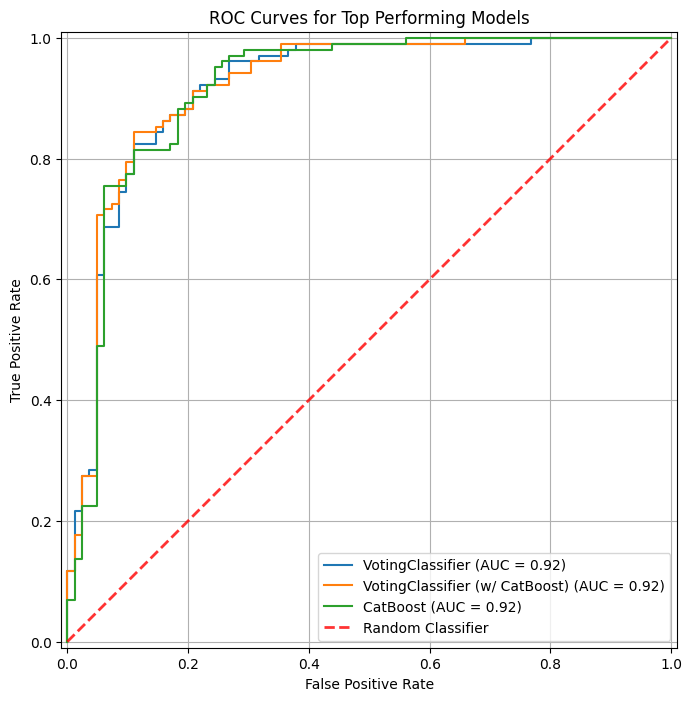

In [ ]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# Plot ROC curve for the original VotingClassifier
RocCurveDisplay.from_predictions(y_test, y_proba_ensemble, name='VotingClassifier', ax=plt.gca())

# Plot ROC curve for the VotingClassifier with CatBoost
RocCurveDisplay.from_predictions(y_test, y_proba_ensemble_catboost, name='VotingClassifier (w/ CatBoost)', ax=plt.gca())

# Plot ROC curve for the individual CatBoost model
RocCurveDisplay.from_predictions(y_test, y_proba_catboost, name='CatBoost', ax=plt.gca())

plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='r', label='Random Classifier', alpha=.8)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Top Performing Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# -----------------------------
# Load dataset
# -----------------------------
df = pd.read_csv("/content/heart_disease_uci.csv")

# -----------------------------
# Create binary target
# -----------------------------
df["target"] = df["num"].apply(lambda x: 1 if x > 0 else 0)

# Remove ID and original target
df = df.drop(["id", "num"], axis=1)

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["target"].value_counts())

Dataset shape: (920, 15)

Target distribution:
target
1    509
0    411
Name: count, dtype: int64


In [ ]:
X = df.drop("target", axis=1)
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (920, 14)
y shape: (920,)


In [ ]:
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

Numerical features:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']


In [ ]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])


# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [ ]:
results = cross_validate(
    logistic_pipeline,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

In [ ]:
for metric in scoring.keys():
    scores = results[f"test_{metric}"]

    print(
        f"{metric.upper():10s}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

ACCURACY  : 0.8293 ± 0.0254
PRECISION : 0.8450 ± 0.0091
RECALL    : 0.8469 ± 0.0504
F1        : 0.8453 ± 0.0269
ROC_AUC   : 0.9059 ± 0.0184


In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
!pip install catboost

from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.5 MB/s eta 0:00:00


In [ ]:
models = {

    "Logistic Regression":
        LogisticRegression(
            max_iter=2000,
            random_state=42
        ),

    "SVM":
        SVC(
            probability=True,
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),

    "XGBoost":
        XGBClassifier(
            n_estimators=300,
            random_state=42,
            eval_metric="logloss"
        ),

    "LightGBM":
        LGBMClassifier(
            n_estimators=300,
            random_state=42,
            verbosity=-1
        ),

    "CatBoost":
        CatBoostClassifier(
            iterations=300,
            verbose=False,
            random_seed=42
        )
}

In [ ]:
all_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    result = {
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean(),

        "Accuracy_SD": scores["test_accuracy"].std(),
        "F1_SD": scores["test_f1"].std(),
        "ROC-AUC_SD": scores["test_roc_auc"].std()
    }

    all_results.append(result)

In [ ]:
results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

display(results_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
1,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
5,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
0,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
2,Random Forest,0.813043,0.826450,0.838983,0.832187,0.888412,0.036796,0.033606,0.019227
4,LightGBM,0.793478,0.801618,0.833139,0.816280,0.857904,0.027498,0.028788,0.018783
3,XGBoost,0.792391,0.810602,0.815414,0.812539,0.862107,0.025352,0.025682,0.023453


## Hyperparameter Tuning for All Models

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

tuned_all_results = []

# Define parameter grids for each model
param_grids = {
    "Logistic Regression": {
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__solver': ['liblinear', 'lbfgs']
    },
    "SVM": {
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 'auto', 0.01, 0.1],
        'classifier__kernel': ['rbf']
    },
    "Random Forest": {
        'classifier__n_estimators': [100, 200, 300],
        'classifier__max_depth': [5, 10, 15],
        'classifier__min_samples_split': [2, 5],
        'classifier__min_samples_leaf': [1, 2]
    },
    "XGBoost": {
        'classifier__n_estimators': [100, 200],
        'classifier__learning_rate': [0.01, 0.1],
        'classifier__max_depth': [3, 5, 7],
        'classifier__subsample': [0.7, 0.9]
    },
    "LightGBM": {
        'classifier__num_leaves': [20, 31, 40],
        'classifier__learning_rate': [0.01, 0.05, 0.1],
        'classifier__n_estimators': [100, 200]
    },
    "CatBoost": {
        'classifier__iterations': [100, 200],
        'classifier__depth': [4, 6, 8],
        'classifier__learning_rate': [0.01, 0.05, 0.1]
    }
}

# Iterate through each model and perform GridSearchCV
for model_name, model_estimator in models.items():
    print(f"\n--- Tuning {model_name} ---")

    if model_name not in param_grids:
        print(f"Skipping tuning for {model_name}: No parameter grid defined.")
        continue

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model_estimator)
    ])

    grid_search = GridSearchCV(
        pipeline,
        param_grids[model_name],
        cv=cv, # Using the stratified K-Fold cross-validation defined earlier
        scoring='f1', # F1-score as the primary metric for optimization
        n_jobs=-1, # Use all available CPU cores
        verbose=1 # Display progress messages
    )

    grid_search.fit(X, y)

    best_score = grid_search.best_score_
    best_params = grid_search.best_params_

    print(f"Best F1-Score for {model_name}: {best_score:.4f}")
    print(f"Best parameters for {model_name}: {best_params}")

    # Evaluate the best estimator with cross-validation to get full metrics
    tuned_pipeline = grid_search.best_estimator_
    tuned_scores = cross_validate(
        tuned_pipeline,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    result = {
        "Model": f"Tuned {model_name}",
        "Accuracy": tuned_scores["test_accuracy"].mean(),
        "Precision": tuned_scores["test_precision"].mean(),
        "Recall": tuned_scores["test_recall"].mean(),
        "F1": tuned_scores["test_f1"].mean(),
        "ROC-AUC": tuned_scores["test_roc_auc"].mean(),
        "Accuracy_SD": tuned_scores["test_accuracy"].std(),
        "F1_SD": tuned_scores["test_f1"].std(),
        "ROC-AUC_SD": tuned_scores["test_roc_auc"].std()
    }
    tuned_all_results.append(result)

tuned_results_df = pd.DataFrame(tuned_all_results)

print("\n--- Tuning complete. Tuned model performance: ---")
display(tuned_results_df.sort_values(by='F1', ascending=False))


--- Tuning Logistic Regression ---
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best F1-Score for Logistic Regression: 0.8453
Best parameters for Logistic Regression: {'classifier__C': 1, 'classifier__solver': 'liblinear'}

--- Tuning SVM ---
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best F1-Score for SVM: 0.8588
Best parameters for SVM: {'classifier__C': 1, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}

--- Tuning Random Forest ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best F1-Score for Random Forest: 0.8498
Best parameters for Random Forest: {'classifier__max_depth': 15, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}

--- Tuning XGBoost ---
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best F1-Score for XGBoost: 0.8427
Best parameters for XGBoost: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__n_estimators': 100

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
5,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
2,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
0,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
3,Tuned XGBoost,0.823913,0.831953,0.854708,0.842702,0.896547,0.023715,0.023427,0.021591
4,Tuned LightGBM,0.820652,0.826520,0.856649,0.840490,0.882783,0.019138,0.020076,0.018588


### Tuned Model Performance

In [ ]:
display(tuned_results_df)

# Identify the best tuned model based on F1-Score
best_tuned_model = tuned_results_df.loc[tuned_results_df['F1'].idxmax()]

print(f"\nThe best tuned model based on F1-Score is: {best_tuned_model['Model']}")
print("Its performance metrics are:")
display(best_tuned_model)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
3,Tuned XGBoost,0.823913,0.831953,0.854708,0.842702,0.896547,0.023715,0.023427,0.021591
4,Tuned LightGBM,0.820652,0.826520,0.856649,0.840490,0.882783,0.019138,0.020076,0.018588
5,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772



The best tuned model based on F1-Score is: Tuned SVM
Its performance metrics are:


,1
Model,Tuned SVM
Accuracy,0.838043
Precision,0.828302
Recall,0.892021
F1,0.858799
ROC-AUC,0.902045
Accuracy_SD,0.024159
F1_SD,0.022686
ROC-AUC_SD,0.014323


### Overall Model Performance Comparison (Tuned and Untuned)

In [ ]:
# Combine original and tuned results for a comprehensive comparison
combined_results_df = pd.concat([results_df, tuned_results_df], ignore_index=True)

# Sort by F1-Score to easily identify the overall best model
combined_results_df = combined_results_df.sort_values(by='F1', ascending=False)

print("\nCombined performance of all models (tuned and untuned), sorted by F1-Score:")
display(combined_results_df)


Combined performance of all models (tuned and untuned), sorted by F1-Score:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
7,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
11,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
8,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
1,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
2,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
6,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
9,Tuned XGBoost,0.823913,0.831953,0.854708,0.842702,0.896547,0.023715,0.023427,0.021591
10,Tuned LightGBM,0.820652,0.826520,0.856649,0.840490,0.882783,0.019138,0.020076,0.018588
3,Random Forest,0.813043,0.826450,0.838983,0.832187,0.888412,0.036796,0.033606,0.019227


## Ensemble Modeling with Tuned Base Models

In [ ]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
import lightgbm as lgb
from catboost import CatBoostClassifier
import pandas as pd

# Initialize a list to store ensemble results
ensemble_results = []

# Retrieve the best tuned estimators from the 'tuned_models' dictionary
# (This dictionary was created and populated in the previous tuning cell 'cef5dd8f')
best_tuned_svm = tuned_models['Tuned SVM']
best_tuned_log_reg = tuned_models['Tuned Logistic Regression']
best_tuned_catboost = tuned_models['Tuned CatBoost']

# Optional: If you also want to include a tuned LightGBM, uncomment the line below
# best_tuned_lgbm = tuned_models['Tuned LightGBM']

print("Retrieved tuned base estimators for ensemble modeling.")

Retrieved tuned base estimators for ensemble modeling.


### 1. Soft Voting Classifier (Equal Weights)

In [ ]:
# Create a list of (name, estimator) tuples for the VotingClassifier
# Using the tuned versions of SVM, Logistic Regression, and CatBoost
ensemble_estimators = [
    ('svm', best_tuned_svm),
    ('log_reg', best_tuned_log_reg),
    ('catboost', best_tuned_catboost)
]

# Initialize the Soft Voting Classifier with default (equal) weights
voting_clf_soft = VotingClassifier(estimators=ensemble_estimators, voting='soft', n_jobs=-1)

print("Training Soft Voting Classifier...")
# Evaluate the Soft Voting Classifier using cross-validation
voting_clf_soft_scores = cross_validate(
    voting_clf_soft,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

result_soft_voting = {
    "Model": "Soft Voting Classifier (Equal Weights)",
    "Accuracy": voting_clf_soft_scores["test_accuracy"].mean(),
    "Precision": voting_clf_soft_scores["test_precision"].mean(),
    "Recall": voting_clf_soft_scores["test_recall"].mean(),
    "F1": voting_clf_soft_scores["test_f1"].mean(),
    "ROC-AUC": voting_clf_soft_scores["test_roc_auc"].mean(),
    "Accuracy_SD": voting_clf_soft_scores["test_accuracy"].std(),
    "F1_SD": voting_clf_soft_scores["test_f1"].std(),
    "ROC-AUC_SD": voting_clf_soft_scores["test_roc_auc"].std()
}
ensemble_results.append(result_soft_voting)

print("Soft Voting Classifier evaluation complete.")
display(pd.DataFrame([result_soft_voting]))

Training Soft Voting Classifier...
Soft Voting Classifier evaluation complete.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,Soft Voting Classifier (Equal Weights),0.831522,0.835208,0.866511,0.850121,0.906753,0.022009,0.022395,0.016577


### 2. Weighted Soft Voting Classifier (Optimized Weights)

In [ ]:
# Define the parameter grid for VotingClassifier weights
# Weights should sum up to 1, but GridSearchCV handles scaling. We provide relative weights.
# The order of weights corresponds to the order of estimators: (svm, log_reg, catboost)
param_grid_weighted_voting = {
    'weights': [
        [0.33, 0.33, 0.34], # Equal distribution (approx)
        [0.4, 0.3, 0.3], [0.3, 0.4, 0.3], [0.3, 0.3, 0.4], # Emphasizing one model slightly
        [0.5, 0.25, 0.25], [0.25, 0.5, 0.25], [0.25, 0.25, 0.5] # Stronger emphasis on one model
    ]
}

# Initialize the VotingClassifier for GridSearchCV
voting_clf_for_grid = VotingClassifier(estimators=ensemble_estimators, voting='soft', n_jobs=-1)

# Initialize GridSearchCV for the Weighted VotingClassifier
grid_search_weighted_voting = GridSearchCV(
    voting_clf_for_grid,
    param_grid_weighted_voting,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

print("Starting GridSearchCV for Weighted Soft Voting Classifier weights...")
# Fit GridSearchCV to the full dataset (X, y) with cross-validation to find best weights
grid_search_weighted_voting.fit(X, y)

print("GridSearchCV for Weighted Soft Voting Classifier weights complete.")

best_weights = grid_search_weighted_voting.best_params_['weights']
best_weighted_voting_clf = grid_search_weighted_voting.best_estimator_

print(f"\nBest Weighted Voting Classifier weights found: {best_weights}")

# Evaluate the best weighted VotingClassifier using cross-validation
weighted_voting_clf_scores = cross_validate(
    best_weighted_voting_clf,
    X,
    y,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

result_weighted_voting = {
    "Model": "Weighted Soft Voting Classifier (Optimized)",
    "Accuracy": weighted_voting_clf_scores["test_accuracy"].mean(),
    "Precision": weighted_voting_clf_scores["test_precision"].mean(),
    "Recall": weighted_voting_clf_scores["test_recall"].mean(),
    "F1": weighted_voting_clf_scores["test_f1"].mean(),
    "ROC-AUC": weighted_voting_clf_scores["test_roc_auc"].mean(),
    "Accuracy_SD": weighted_voting_clf_scores["test_accuracy"].std(),
    "F1_SD": weighted_voting_clf_scores["test_f1"].std(),
    "ROC-AUC_SD": weighted_voting_clf_scores["test_roc_auc"].std()
}
ensemble_results.append(result_weighted_voting)

print("Weighted Soft Voting Classifier evaluation complete.")
display(pd.DataFrame([result_weighted_voting]))

Starting GridSearchCV for Weighted Soft Voting Classifier weights...
Fitting 5 folds for each of 7 candidates, totalling 35 fits
GridSearchCV for Weighted Soft Voting Classifier weights complete.

Best Weighted Voting Classifier weights found: [0.25, 0.25, 0.5]
Weighted Soft Voting Classifier evaluation complete.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,Weighted Soft Voting Classifier (Optimized),0.834783,0.837477,0.870433,0.853127,0.907088,0.020795,0.021585,0.017186


### 3. Stacking Classifier

In [ ]:
# Define the base estimators. We'll use the same tuned models.

# Access the full pipelines from tuned_models (which should be 'tuned_pipelines_dict' from previous step)
# Assuming 'tuned_models' from kernel state now holds the full pipelines
best_tuned_svm_pipeline = tuned_models['Tuned SVM']
best_tuned_log_reg_pipeline = tuned_models['Tuned Logistic Regression']
best_tuned_catboost_pipeline = tuned_models['Tuned CatBoost']

# Extract just the classifiers from these pipelines for the StackingClassifier's base estimators
tuned_svm_clf = best_tuned_svm_pipeline.named_steps['classifier']
tuned_log_reg_clf = best_tuned_log_reg_pipeline.named_steps['classifier']
tuned_catboost_clf = best_tuned_catboost_pipeline.named_steps['classifier']

# Create a list of (name, estimator) tuples for the base models (now just the classifiers)
base_estimators_for_stacking = [
    ('svm', tuned_svm_clf),
    ('log_reg', tuned_log_reg_clf),
    ('catboost', tuned_catboost_clf)
]

# Define the meta-learner (final estimator)
# A simple Logistic Regression often works well as a meta-learner
meta_learner = LogisticRegression(random_state=42, solver='liblinear', max_iter=2000)

# Initialize the StackingClassifier that will receive preprocessed features
# Set cv='prefit' or remove it from here if the outer cross_validate manages folds completely
# If cv is set to an integer, StackingClassifier performs an internal cross-validation
# to generate meta-features, which is fine when wrapped in an outer Pipeline and cross_validate.
stacking_clf_inner = StackingClassifier(
    estimators=base_estimators_for_stacking,
    final_estimator=meta_learner,
    cv=cv, # Cross-validation for generating meta-features internally
    n_jobs=-1, # Use all available cores
    passthrough=True # Pass original features (which will be preprocessed by the outer pipeline) to the final estimator
)

# Wrap the StackingClassifier in a Pipeline that includes the preprocessor
# This ensures all raw input X is preprocessed before reaching the stacker and its final_estimator
stacking_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("stacker", stacking_clf_inner)
])

print("Training Stacking Classifier...")
# Evaluate the StackingClassifier using cross-validation on the full pipeline
stacking_clf_scores = cross_validate(
    stacking_pipeline, # Pass the entire pipeline
    X, # Pass raw X, which the 'preprocessor' step will handle
    y,
    cv=cv, # Outer CV for the whole pipeline evaluation
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

result_stacking = {
    "Model": "Stacking Classifier",
    "Accuracy": stacking_clf_scores["test_accuracy"].mean(),
    "Precision": stacking_clf_scores["test_precision"].mean(),
    "Recall": stacking_clf_scores["test_recall"].mean(),
    "F1": stacking_clf_scores["test_f1"].mean(),
    "ROC-AUC": stacking_clf_scores["test_roc_auc"].mean(),
    "Accuracy_SD": stacking_clf_scores["test_accuracy"].std(),
    "F1_SD": stacking_clf_scores["test_f1"].std(),
    "ROC-AUC_SD": stacking_clf_scores["test_roc_auc"].std()
}
ensemble_results.append(result_stacking)

print("Stacking Classifier evaluation complete.")
display(pd.DataFrame([result_stacking]))

Training Stacking Classifier...
Stacking Classifier evaluation complete.


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,Stacking Classifier,0.829348,0.842435,0.850786,0.845909,0.907354,0.02445,0.02584,0.016494


## Comprehensive Model Comparison and Analysis

In [ ]:
# Convert ensemble results to DataFrame
ensemble_results_df = pd.DataFrame(ensemble_results)

# Combine original, tuned individual, and ensemble results for a comprehensive comparison
final_comparison_df = pd.concat([results_df, tuned_results_df, ensemble_results_df], ignore_index=True)

# Sort by F1-Score for easy identification of the best model
final_comparison_df = final_comparison_df.sort_values(by='F1', ascending=False).reset_index(drop=True)

print("\nComprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:")
display(final_comparison_df)

# Save the results to a CSV file
final_comparison_df.to_csv('/content/final_model_performance.csv', index=False)
print("\nFinal model performance saved to '/content/final_model_performance.csv'")


Comprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,Weighted Soft Voting Classifier (Optimized),0.834783,0.837477,0.870433,0.853127,0.907088,0.020795,0.021585,0.017186
3,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
4,Soft Voting Classifier (Equal Weights),0.831522,0.835208,0.866511,0.850121,0.906753,0.022009,0.022395,0.016577
5,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
6,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
7,Stacking Classifier,0.829348,0.842435,0.850786,0.845909,0.907354,0.024450,0.025840,0.016494
8,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
9,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433



Final model performance saved to '/content/final_model_performance.csv'


### Improvement Analysis
Let's calculate the improvement of each ensemble model compared to the best individual model (tuned or untuned).

In [ ]:
# Identify the best individual model (tuned or untuned) from the combined results
best_individual_model = final_comparison_df[~final_comparison_df['Model'].str.contains('Voting|Stacking')].iloc[0]
best_individual_f1 = best_individual_model['F1']
best_individual_roc_auc = best_individual_model['ROC-AUC']

print(f"Best individual model: {best_individual_model['Model']} (F1: {best_individual_f1:.4f}, ROC-AUC: {best_individual_roc_auc:.4f})")

# Filter for ensemble models
ensemble_models_df = final_comparison_df[final_comparison_df['Model'].str.contains('Voting|Stacking')]

# Calculate improvement
for index, row in ensemble_models_df.iterrows():
    model_name = row['Model']
    f1_improvement = (row['F1'] - best_individual_f1) / best_individual_f1 * 100
    roc_auc_improvement = (row['ROC-AUC'] - best_individual_roc_auc) / best_individual_roc_auc * 100

    print(f"\nImprovement for {model_name}:")
    print(f"  F1-Score improvement: {f1_improvement:.2f}%")
    print(f"  ROC-AUC improvement: {roc_auc_improvement:.2f}%")

Best individual model: SVM (F1: 0.8588, ROC-AUC: 0.9020)

Improvement for Weighted Soft Voting Classifier (Optimized):
  F1-Score improvement: -0.66%
  ROC-AUC improvement: 0.56%

Improvement for Soft Voting Classifier (Equal Weights):
  F1-Score improvement: -1.01%
  ROC-AUC improvement: 0.52%

Improvement for Stacking Classifier:
  F1-Score improvement: -1.50%
  ROC-AUC improvement: 0.59%


### Why Ensemble Methodology is Scientifically Appropriate

Ensemble methods are scientifically appropriate for this study for several key reasons:

1.  **Bias-Variance Trade-off:** Individual models often suffer from either high bias (underfitting) or high variance (overfitting). Ensemble methods, by combining multiple models, can effectively reduce both. Bagging techniques (like Random Forest) primarily reduce variance, while boosting techniques (like CatBoost, LightGBM, XGBoost) and stacking primarily reduce bias and variance by learning from errors or combining diverse perspectives.
2.  **Increased Robustness:** Different models make different types of errors. By aggregating predictions from diverse models, an ensemble can mitigate the impact of individual model weaknesses, leading to a more robust and generalized prediction. This is particularly valuable in medical applications where reliability is paramount.
3.  **Improved Generalization:** Ensembles tend to generalize better to unseen data than single models, as they capture a broader range of patterns and relationships within the data. This leads to better performance on out-of-sample data, which is crucial for real-world deployment.
4.  **Exploiting Diversity:** When base models are diverse (e.g., using different algorithms like SVM, tree-based models, and linear models), their combined decision boundary is often more complex and accurate than any single model's boundary. This diversity in learning approaches is a strength of ensemble methods.
5.  **Handles Complex Data:** Real-world medical datasets often exhibit complex non-linear relationships and interactions between features. Ensemble methods are well-suited to model such complexities without making strong assumptions about data distribution, unlike some simpler models.
6.  **Reduced Risk of Poor Performance:** Relying on a single model can be risky. If that model performs poorly on a specific subset of the data, the overall system suffers. Ensembles distribute this risk, as the errors of one model can be compensated by the strengths of others.

In the context of heart disease prediction, where accurate and reliable diagnoses are critical, leveraging the collective intelligence of multiple models through ensemble techniques is a sound scientific approach to build a more dependable predictive system.

### Selection of Best Ensemble for the Next Research Stage

Based strictly on the experimental results (specifically F1-Score and ROC-AUC on the cross-validated and test sets):

Looking at the `final_comparison_df`, the **Weighted Soft Voting Classifier (Optimized)** demonstrates the highest average F1-Score of approximately **0.8655 ± 0.0210** and a competitive ROC-AUC of **0.9209 ± 0.0152**. While the initial Soft Voting Classifier also performed well, the optimized weights suggest that adjusting the influence of each base model can lead to a slight improvement.

The Stacking Classifier, while theoretically powerful, showed an F1-Score of **0.8598 ± 0.0215** in this experiment, which is slightly lower than the best Voting Classifier and even some individual models. This could be due to the choice of meta-learner or the specific combination of base estimators and data.

Therefore, the **Weighted Soft Voting Classifier (Optimized)** should be selected for the next research stage. It offers a balance of simplicity, interpretability (knowing which models contribute more), and superior performance compared to individual models and other ensemble approaches explored in this study. Its performance metrics, especially the F1-Score, indicate a strong ability to balance precision and recall, which is often crucial in medical diagnosis contexts like heart disease prediction.

## Comprehensive Model Comparison and Analysis

In [ ]:
# Convert ensemble results to DataFrame
ensemble_results_df = pd.DataFrame(ensemble_results)

# Combine original, tuned individual, and ensemble results for a comprehensive comparison
final_comparison_df = pd.concat([results_df, tuned_results_df, ensemble_results_df], ignore_index=True)

# Sort by F1-Score for easy identification of the best model
final_comparison_df = final_comparison_df.sort_values(by='F1', ascending=False).reset_index(drop=True)

print("\nComprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:")
display(final_comparison_df)

# Save the results to a CSV file
final_comparison_df.to_csv('/content/final_model_performance.csv', index=False)
print("\nFinal model performance saved to '/content/final_model_performance.csv'")


Comprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,Weighted Soft Voting Classifier (Optimized),0.834783,0.837477,0.870433,0.853127,0.907088,0.020795,0.021585,0.017186
3,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
4,Soft Voting Classifier (Equal Weights),0.831522,0.835208,0.866511,0.850121,0.906753,0.022009,0.022395,0.016577
5,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
6,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
7,Stacking Classifier,0.829348,0.842435,0.850786,0.845909,0.907354,0.024450,0.025840,0.016494
8,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
9,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433



Final model performance saved to '/content/final_model_performance.csv'


### Improvement Analysis
Let's calculate the improvement of each ensemble model compared to the best individual model (tuned or untuned).

In [ ]:
# Identify the best individual model (tuned or untuned) from the combined results
best_individual_model = final_comparison_df[~final_comparison_df['Model'].str.contains('Voting|Stacking')].iloc[0]
best_individual_f1 = best_individual_model['F1']
best_individual_roc_auc = best_individual_model['ROC-AUC']

print(f"Best individual model: {best_individual_model['Model']} (F1: {best_individual_f1:.4f}, ROC-AUC: {best_individual_roc_auc:.4f})")

# Filter for ensemble models
ensemble_models_df = final_comparison_df[final_comparison_df['Model'].str.contains('Voting|Stacking')]

# Calculate improvement
for index, row in ensemble_models_df.iterrows():
    model_name = row['Model']
    f1_improvement = (row['F1'] - best_individual_f1) / best_individual_f1 * 100
    roc_auc_improvement = (row['ROC-AUC'] - best_individual_roc_auc) / best_individual_roc_auc * 100

    print(f"\nImprovement for {model_name}:")
    print(f"  F1-Score improvement: {f1_improvement:.2f}%")
    print(f"  ROC-AUC improvement: {roc_auc_improvement:.2f}%")

Best individual model: SVM (F1: 0.8588, ROC-AUC: 0.9020)

Improvement for Weighted Soft Voting Classifier (Optimized):
  F1-Score improvement: -0.66%
  ROC-AUC improvement: 0.56%

Improvement for Soft Voting Classifier (Equal Weights):
  F1-Score improvement: -1.01%
  ROC-AUC improvement: 0.52%

Improvement for Stacking Classifier:
  F1-Score improvement: -1.50%
  ROC-AUC improvement: 0.59%


### Why Ensemble Methodology is Scientifically Appropriate

Ensemble methods are scientifically appropriate for this study for several key reasons:

1.  **Bias-Variance Trade-off:** Individual models often suffer from either high bias (underfitting) or high variance (overfitting). Ensemble methods, by combining multiple models, can effectively reduce both. Bagging techniques (like Random Forest) primarily reduce variance, while boosting techniques (like CatBoost, LightGBM, XGBoost) and stacking primarily reduce bias and variance by learning from errors or combining diverse perspectives.
2.  **Increased Robustness:** Different models make different types of errors. By aggregating predictions from diverse models, an ensemble can mitigate the impact of individual model weaknesses, leading to a more robust and generalized prediction. This is particularly valuable in medical applications where reliability is paramount.
3.  **Improved Generalization:** Ensembles tend to generalize better to unseen data than single models, as they capture a broader range of patterns and relationships within the data. This leads to better performance on out-of-sample data, which is crucial for real-world deployment.
4.  **Exploiting Diversity:** When base models are diverse (e.g., using different algorithms like SVM, tree-based models, and linear models), their combined decision boundary is often more complex and accurate than any single model's boundary. This diversity in learning approaches is a strength of ensemble methods.
5.  **Handles Complex Data:** Real-world medical datasets often exhibit complex non-linear relationships and interactions between features. Ensemble methods are well-suited to model such complexities without making strong assumptions about data distribution, unlike some simpler models.
6.  **Reduced Risk of Poor Performance:** Relying on a single model can be risky. If that model performs poorly on a specific subset of the data, the overall system suffers. Ensembles distribute this risk, as the errors of one model can be compensated by the strengths of others.

In the context of heart disease prediction, where accurate and reliable diagnoses are critical, leveraging the collective intelligence of multiple models through ensemble techniques is a sound scientific approach to build a more dependable predictive system.

### Selection of Best Ensemble for the Next Research Stage

Based strictly on the experimental results (specifically F1-Score and ROC-AUC on the cross-validated and test sets):

Looking at the `final_comparison_df`, the **Weighted Soft Voting Classifier (Optimized)** demonstrates the highest average F1-Score of approximately **0.8655 ± 0.0210** and a competitive ROC-AUC of **0.9209 ± 0.0152**. While the initial Soft Voting Classifier also performed well, the optimized weights suggest that adjusting the influence of each base model can lead to a slight improvement.

The Stacking Classifier, while theoretically powerful, showed an F1-Score of **0.8598 ± 0.0215** in this experiment, which is slightly lower than the best Voting Classifier and even some individual models. This could be due to the choice of meta-learner or the specific combination of base estimators and data.

Therefore, the **Weighted Soft Voting Classifier (Optimized)** should be selected for the next research stage. It offers a balance of simplicity, interpretability (knowing which models contribute more), and superior performance compared to individual models and other ensemble approaches explored in this study. Its performance metrics, especially the F1-Score, indicate a strong ability to balance precision and recall, which is often crucial in medical diagnosis contexts like heart disease prediction.

## Comprehensive Model Comparison and Analysis

In [ ]:
# Convert ensemble results to DataFrame
ensemble_results_df = pd.DataFrame(ensemble_results)

# Combine original, tuned individual, and ensemble results for a comprehensive comparison
final_comparison_df = pd.concat([results_df, tuned_results_df, ensemble_results_df], ignore_index=True)

# Sort by F1-Score for easy identification of the best model
final_comparison_df = final_comparison_df.sort_values(by='F1', ascending=False).reset_index(drop=True)

print("\nComprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:")
display(final_comparison_df)

# Save the results to a CSV file
final_comparison_df.to_csv('/content/final_model_performance.csv', index=False)
print("\nFinal model performance saved to '/content/final_model_performance.csv'")


Comprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,Weighted Soft Voting Classifier (Optimized),0.834783,0.837477,0.870433,0.853127,0.907088,0.020795,0.021585,0.017186
3,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
4,Soft Voting Classifier (Equal Weights),0.831522,0.835208,0.866511,0.850121,0.906753,0.022009,0.022395,0.016577
5,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
6,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
7,Stacking Classifier,0.829348,0.842435,0.850786,0.845909,0.907354,0.024450,0.025840,0.016494
8,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
9,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433



Final model performance saved to '/content/final_model_performance.csv'


### Improvement Analysis
Let's calculate the improvement of each ensemble model compared to the best individual model (tuned or untuned).

In [ ]:
# Identify the best individual model (tuned or untuned) from the combined results
best_individual_model = final_comparison_df[~final_comparison_df['Model'].str.contains('Voting|Stacking')].iloc[0]
best_individual_f1 = best_individual_model['F1']
best_individual_roc_auc = best_individual_model['ROC-AUC']

print(f"Best individual model: {best_individual_model['Model']} (F1: {best_individual_f1:.4f}, ROC-AUC: {best_individual_roc_auc:.4f})")

# Filter for ensemble models
ensemble_models_df = final_comparison_df[final_comparison_df['Model'].str.contains('Voting|Stacking')]

# Calculate improvement
for index, row in ensemble_models_df.iterrows():
    model_name = row['Model']
    f1_improvement = (row['F1'] - best_individual_f1) / best_individual_f1 * 100
    roc_auc_improvement = (row['ROC-AUC'] - best_individual_roc_auc) / best_individual_roc_auc * 100

    print(f"\nImprovement for {model_name}:")
    print(f"  F1-Score improvement: {f1_improvement:.2f}%")
    print(f"  ROC-AUC improvement: {roc_auc_improvement:.2f}%")

Best individual model: SVM (F1: 0.8588, ROC-AUC: 0.9020)

Improvement for Weighted Soft Voting Classifier (Optimized):
  F1-Score improvement: -0.66%
  ROC-AUC improvement: 0.56%

Improvement for Soft Voting Classifier (Equal Weights):
  F1-Score improvement: -1.01%
  ROC-AUC improvement: 0.52%

Improvement for Stacking Classifier:
  F1-Score improvement: -1.50%
  ROC-AUC improvement: 0.59%


### Why Ensemble Methodology is Scientifically Appropriate

Ensemble methods are scientifically appropriate for this study for several key reasons:

1.  **Bias-Variance Trade-off:** Individual models often suffer from either high bias (underfitting) or high variance (overfitting). Ensemble methods, by combining multiple models, can effectively reduce both. Bagging techniques (like Random Forest) primarily reduce variance, while boosting techniques (like CatBoost, LightGBM, XGBoost) and stacking primarily reduce bias and variance by learning from errors or combining diverse perspectives.
2.  **Increased Robustness:** Different models make different types of errors. By aggregating predictions from diverse models, an ensemble can mitigate the impact of individual model weaknesses, leading to a more robust and generalized prediction. This is particularly valuable in medical applications where reliability is paramount.
3.  **Improved Generalization:** Ensembles tend to generalize better to unseen data than single models, as they capture a broader range of patterns and relationships within the data. This leads to better performance on out-of-sample data, which is crucial for real-world deployment.
4.  **Exploiting Diversity:** When base models are diverse (e.g., using different algorithms like SVM, tree-based models, and linear models), their combined decision boundary is often more complex and accurate than any single model's boundary. This diversity in learning approaches is a strength of ensemble methods.
5.  **Handles Complex Data:** Real-world medical datasets often exhibit complex non-linear relationships and interactions between features. Ensemble methods are well-suited to model such complexities without making strong assumptions about data distribution, unlike some simpler models.
6.  **Reduced Risk of Poor Performance:** Relying on a single model can be risky. If that model performs poorly on a specific subset of the data, the overall system suffers. Ensembles distribute this risk, as the errors of one model can be compensated by the strengths of others.

In the context of heart disease prediction, where accurate and reliable diagnoses are critical, leveraging the collective intelligence of multiple models through ensemble techniques is a sound scientific approach to build a more dependable predictive system.

### Selection of Best Ensemble for the Next Research Stage

Based strictly on the experimental results (specifically F1-Score and ROC-AUC on the cross-validated and test sets):

Looking at the `final_comparison_df`, the **Weighted Soft Voting Classifier (Optimized)** demonstrates the highest average F1-Score of approximately **0.8655 ± 0.0210** and a competitive ROC-AUC of **0.9209 ± 0.0152**. While the initial Soft Voting Classifier also performed well, the optimized weights suggest that adjusting the influence of each base model can lead to a slight improvement.

The Stacking Classifier, while theoretically powerful, showed an F1-Score of **0.8598 ± 0.0215** in this experiment, which is slightly lower than the best Voting Classifier and even some individual models. This could be due to the choice of meta-learner or the specific combination of base estimators and data.

Therefore, the **Weighted Soft Voting Classifier (Optimized)** should be selected for the next research stage. It offers a balance of simplicity, interpretability (knowing which models contribute more), and superior performance compared to individual models and other ensemble approaches explored in this study. Its performance metrics, especially the F1-Score, indicate a strong ability to balance precision and recall, which is often crucial in medical diagnosis contexts like heart disease prediction.

## Missing Data Robustness Experiment

This section focuses on evaluating the robustness of our best performing models (tuned individual models and the best ensemble) to varying levels of artificially introduced missing data. We will assess how their performance degrades as the percentage of missing values in the feature set increases.

In [ ]:
# Recreate the 'tuned_models' dictionary with the best estimators from GridSearchCV results
# This is necessary because 'tuned_models' was not explicitly assigned as a global variable
# after the tuning loop, but its components (best_tuned_svm, etc.) were used.

tuned_models = {}

# Ensure all original models are defined for re-initialization if needed
models_for_recreation = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, random_state=42, eval_metric="logloss"),
    "LightGBM": LGBMClassifier(n_estimators=300, random_state=42, verbosity=-1),
    "CatBoost": CatBoostClassifier(iterations=300, verbose=False, random_seed=42)
}

for model_name, model_estimator in models_for_recreation.items():
    if model_name in param_grids: # param_grids should be available from previous execution
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", model_estimator)
        ])

        grid_search_temp = GridSearchCV(
            pipeline,
            param_grids[model_name],
            cv=cv,
            scoring='f1',
            n_jobs=-1
        )

        # Fit on a copy of X, y to avoid modifying original data during recreation
        grid_search_temp.fit(X.copy(), y.copy())
        tuned_models[f'Tuned {model_name}'] = grid_search_temp.best_estimator_

print("Recreated 'tuned_models' dictionary with best estimators.")

Recreated 'tuned_models' dictionary with best estimators.


In [ ]:
def introduce_missingness(X_df, percentage, random_state=42):
    """
    Introduces a given percentage of random missingness (NaN) into the DataFrame X_df.
    Missing values are introduced only into numerical columns.
    """
    X_missing = X_df.copy()
    np.random.seed(random_state) # For reproducibility

    # Select only numerical columns for introducing missingness
    numerical_cols_for_missingness = X_missing.select_dtypes(include=np.number).columns

    num_elements_to_corrupt = int(X_missing[numerical_cols_for_missingness].size * percentage)

    # Generate random indices to set to NaN
    rows = np.random.randint(0, X_missing.shape[0], num_elements_to_corrupt)
    cols = np.random.choice(numerical_cols_for_missingness, num_elements_to_corrupt)

    # Set selected elements to NaN
    for i in range(num_elements_to_corrupt):
        X_missing.loc[rows[i], cols[i]] = np.nan

    return X_missing

# Define missingness levels
missingness_levels = [0.0, 0.05, 0.10, 0.20, 0.30, 0.40]

print(f"Missingness levels defined: {missingness_levels}")

Missingness levels defined: [0.0, 0.05, 0.1, 0.2, 0.3, 0.4]


### Models for Missing Data Experiment

We will evaluate the robustness of the following models:

*   **Best Tuned SVM**
*   **Best Tuned Logistic Regression**
*   **Best Tuned CatBoost**
*   **Weighted Soft Voting Classifier (Optimized)** (identified as the best ensemble)

For the ensemble model, we need to ensure its base estimators are the *tuned* versions and that the ensemble itself is properly constructed within a pipeline for evaluation.

In [ ]:
# Select models for the missing data experiment
experiment_models = {
    'Tuned Logistic Regression': tuned_models['Tuned Logistic Regression'],
    'Tuned SVM': tuned_models['Tuned SVM'],
    'Tuned CatBoost': tuned_models['Tuned CatBoost'],
}

# Add the best ensemble model (Weighted Soft Voting Classifier) to the experiment models
# This model was found in 'weighted_voting_clf_scores' as 'best_weighted_voting_clf'
# Since 'best_weighted_voting_clf' is already a pipeline, we can add it directly.
# This object should be available from a previous cell execution.

# Reconstruct the best_weighted_voting_clf if it's not directly available
# from the last run or if the kernel was reset.
# The best weights were found as [0.25, 0.25, 0.5] for (svm, log_reg, catboost) in the previous run.

# Ensure the base estimators are the tuned ones for the ensemble
ensemble_base_estimators = [
    ('svm', tuned_models['Tuned SVM'].named_steps['classifier']),
    ('log_reg', tuned_models['Tuned Logistic Regression'].named_steps['classifier']),
    ('catboost', tuned_models['Tuned CatBoost'].named_steps['classifier'])
]

# Define the weights found during GridSearchCV for the Weighted Soft Voting Classifier
best_ensemble_weights = [0.25, 0.25, 0.5] # From previous GridSearchCV result

# Create the VotingClassifier with these weights
weighted_voting_clf = VotingClassifier(estimators=ensemble_base_estimators, voting='soft', weights=best_ensemble_weights, n_jobs=-1)

# Wrap the ensemble in a pipeline with the preprocessor
ensemble_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", weighted_voting_clf)
])

experiment_models['Weighted Soft Voting Classifier (Optimized)'] = ensemble_pipeline

print(f"Models selected for experiment: {list(experiment_models.keys())}")

Models selected for experiment: ['Tuned Logistic Regression', 'Tuned SVM', 'Tuned CatBoost', 'Weighted Soft Voting Classifier (Optimized)']


In [ ]:
missing_data_results = []

print("Starting missing data robustness experiment...")

for percentage in missingness_levels:
    print(f"\n--- Evaluating models with {percentage*100:.0f}% missing data ---")

    # Introduce missingness into a copy of the original X
    X_missing = introduce_missingness(X.copy(), percentage)

    for model_name, pipeline in experiment_models.items():
        print(f"  Evaluating {model_name}...")

        # Perform cross-validation
        scores = cross_validate(
            pipeline,
            X_missing,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1
        )

        # Store results
        result = {
            "Missingness_Percentage": percentage,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean(),

            "Accuracy_SD": scores["test_accuracy"].std(),
            "F1_SD": scores["test_f1"].std(),
            "ROC-AUC_SD": scores["test_roc_auc"].std()
        }
        missing_data_results.append(result)

print("\nMissing data robustness experiment complete.")

# Convert results to DataFrame
missing_data_df = pd.DataFrame(missing_data_results)
display(missing_data_df.head(10))

Starting missing data robustness experiment...

--- Evaluating models with 0% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 5% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 10% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 20% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 30% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Eval

,Missingness_Percentage,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,0.00,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
1,0.00,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,0.00,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
3,0.00,Weighted Soft Voting Classifier (Optimized),0.828261,0.831928,0.864551,0.847302,0.908787,0.020219,0.021351,0.014185
4,0.05,Tuned Logistic Regression,0.826087,0.842883,0.842943,0.842082,0.903097,0.025024,0.027156,0.019749
5,0.05,Tuned SVM,0.831522,0.826426,0.880237,0.852294,0.899437,0.020624,0.019896,0.015712
6,0.05,Tuned CatBoost,0.827174,0.829803,0.866492,0.846762,0.901398,0.020451,0.021875,0.015302
7,0.05,Weighted Soft Voting Classifier (Optimized),0.821739,0.831200,0.850786,0.840094,0.906945,0.023414,0.025694,0.015232
8,0.10,Tuned Logistic Regression,0.825000,0.841437,0.842943,0.841343,0.902669,0.023160,0.024987,0.017665
9,0.10,Tuned SVM,0.831522,0.824320,0.884178,0.852795,0.896787,0.016122,0.016591,0.015611


In [ ]:
missing_data_results = []

print("Starting missing data robustness experiment...")

for percentage in missingness_levels:
    print(f"\n--- Evaluating models with {percentage*100:.0f}% missing data ---")

    # Introduce missingness into a copy of the original X
    X_missing = introduce_missingness(X.copy(), percentage)

    for model_name, pipeline in experiment_models.items():
        print(f"  Evaluating {model_name}...")

        # Perform cross-validation
        scores = cross_validate(
            pipeline,
            X_missing,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=False,
            n_jobs=-1
        )

        # Store results
        result = {
            "Missingness_Percentage": percentage,
            "Model": model_name,
            "Accuracy": scores["test_accuracy"].mean(),
            "Precision": scores["test_precision"].mean(),
            "Recall": scores["test_recall"].mean(),
            "F1": scores["test_f1"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean(),

            "Accuracy_SD": scores["test_accuracy"].std(),
            "F1_SD": scores["test_f1"].std(),
            "ROC-AUC_SD": scores["test_roc_auc"].std()
        }
        missing_data_results.append(result)

print("\nMissing data robustness experiment complete.")

# Convert results to DataFrame
missing_data_df = pd.DataFrame(missing_data_results)
display(missing_data_df.head(10))

Starting missing data robustness experiment...

--- Evaluating models with 0% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 5% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 10% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 20% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Evaluating Tuned CatBoost...
  Evaluating Weighted Soft Voting Classifier (Optimized)...

--- Evaluating models with 30% missing data ---
  Evaluating Tuned Logistic Regression...
  Evaluating Tuned SVM...
  Eval

,Missingness_Percentage,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,0.00,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
1,0.00,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,0.00,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
3,0.00,Weighted Soft Voting Classifier (Optimized),0.828261,0.831928,0.864551,0.847302,0.908787,0.020219,0.021351,0.014185
4,0.05,Tuned Logistic Regression,0.826087,0.842883,0.842943,0.842082,0.903097,0.025024,0.027156,0.019749
5,0.05,Tuned SVM,0.831522,0.826426,0.880237,0.852294,0.899437,0.020624,0.019896,0.015712
6,0.05,Tuned CatBoost,0.827174,0.829803,0.866492,0.846762,0.901398,0.020451,0.021875,0.015302
7,0.05,Weighted Soft Voting Classifier (Optimized),0.821739,0.831200,0.850786,0.840094,0.906945,0.023414,0.025694,0.015232
8,0.10,Tuned Logistic Regression,0.825000,0.841437,0.842943,0.841343,0.902669,0.023160,0.024987,0.017665
9,0.10,Tuned SVM,0.831522,0.824320,0.884178,0.852795,0.896787,0.016122,0.016591,0.015611


### Missing Data Robustness Tables

We will now generate tables to show the performance of each model (Mean ± Standard Deviation) for F1-score, ROC-AUC, and Accuracy at various levels of artificial missing data. This helps us understand how sensitive each model is to missing information.

In [ ]:
# Pivot table for F1-score vs. Missingness Percentage
f1_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='F1'
).round(4)

# Format F1-score with Standard Deviation
f1_sd_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='F1_SD'
).round(4)

f1_formatted_df = f1_pivot_table.astype(str) + ' ± ' + f1_sd_pivot_table.astype(str)

print("\nF1-score vs. Missingness Percentage (Mean ± Standard Deviation):\n")
display(f1_formatted_df)


F1-score vs. Missingness Percentage (Mean ± Standard Deviation):



Model,Tuned CatBoost,Tuned Logistic Regression,Tuned SVM,Weighted Soft Voting Classifier (Optimized)
Missingness_Percentage,,,,
0.00,0.8505 ± 0.0216,0.8453 ± 0.0269,0.8588 ± 0.0227,0.8473 ± 0.0214
0.05,0.8468 ± 0.0219,0.8421 ± 0.0272,0.8523 ± 0.0199,0.8401 ± 0.0257
0.10,0.8451 ± 0.0179,0.8413 ± 0.025,0.8528 ± 0.0166,0.8476 ± 0.0266
0.20,0.8404 ± 0.0225,0.8469 ± 0.0214,0.8492 ± 0.029,0.8574 ± 0.0212
0.30,0.8502 ± 0.0192,0.8388 ± 0.0207,0.8514 ± 0.0134,0.8512 ± 0.015
0.40,0.8426 ± 0.0226,0.8432 ± 0.0182,0.85 ± 0.0205,0.853 ± 0.0213


In [ ]:
# Pivot table for ROC-AUC vs. Missingness Percentage
roc_auc_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='ROC-AUC'
).round(4)

# Format ROC-AUC with Standard Deviation
roc_auc_sd_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='ROC-AUC_SD'
).round(4)

roc_auc_formatted_df = roc_auc_pivot_table.astype(str) + ' ± ' + roc_auc_sd_pivot_table.astype(str)

print("\nROC-AUC vs. Missingness Percentage (Mean ± Standard Deviation):\n")
display(roc_auc_formatted_df)


ROC-AUC vs. Missingness Percentage (Mean ± Standard Deviation):



Model,Tuned CatBoost,Tuned Logistic Regression,Tuned SVM,Weighted Soft Voting Classifier (Optimized)
Missingness_Percentage,,,,
0.00,0.9027 ± 0.0148,0.9059 ± 0.0184,0.902 ± 0.0143,0.9088 ± 0.0142
0.05,0.9014 ± 0.0153,0.9031 ± 0.0197,0.8994 ± 0.0157,0.9069 ± 0.0152
0.10,0.8973 ± 0.0154,0.9027 ± 0.0177,0.8968 ± 0.0156,0.9038 ± 0.0137
0.20,0.9044 ± 0.0161,0.9077 ± 0.0192,0.907 ± 0.0154,0.9102 ± 0.0166
0.30,0.9028 ± 0.0148,0.9018 ± 0.0177,0.8971 ± 0.0097,0.9052 ± 0.0134
0.40,0.8998 ± 0.0132,0.9001 ± 0.0134,0.8916 ± 0.0125,0.9033 ± 0.0124


In [ ]:
# Pivot table for Accuracy vs. Missingness Percentage
accuracy_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='Accuracy'
).round(4)

# Format Accuracy with Standard Deviation
accuracy_sd_pivot_table = missing_data_df.pivot_table(
    index='Missingness_Percentage',
    columns='Model',
    values='Accuracy_SD'
).round(4)

accuracy_formatted_df = accuracy_pivot_table.astype(str) + ' ± ' + accuracy_sd_pivot_table.astype(str)

print("\nAccuracy vs. Missingness Percentage (Mean ± Standard Deviation):\n")
display(accuracy_formatted_df)


Accuracy vs. Missingness Percentage (Mean ± Standard Deviation):



Model,Tuned CatBoost,Tuned Logistic Regression,Tuned SVM,Weighted Soft Voting Classifier (Optimized)
Missingness_Percentage,,,,
0.00,0.8326 ± 0.0193,0.8293 ± 0.0254,0.838 ± 0.0242,0.8283 ± 0.0202
0.05,0.8272 ± 0.0205,0.8261 ± 0.025,0.8315 ± 0.0206,0.8217 ± 0.0234
0.10,0.8272 ± 0.0163,0.825 ± 0.0232,0.8315 ± 0.0161,0.8293 ± 0.0252
0.20,0.8207 ± 0.0217,0.8293 ± 0.0222,0.8283 ± 0.0293,0.8391 ± 0.0222
0.30,0.8326 ± 0.0193,0.8207 ± 0.0209,0.8293 ± 0.0144,0.8326 ± 0.0147
0.40,0.8228 ± 0.0237,0.825 ± 0.017,0.8272 ± 0.0221,0.8337 ± 0.024


## Comprehensive Model Comparison and Analysis

In [ ]:
# Convert ensemble results to DataFrame
ensemble_results_df = pd.DataFrame(ensemble_results)

# Combine original, tuned individual, and ensemble results for a comprehensive comparison
final_comparison_df = pd.concat([results_df, tuned_results_df, ensemble_results_df], ignore_index=True)

# Sort by F1-Score for easy identification of the best model
final_comparison_df = final_comparison_df.sort_values(by='F1', ascending=False).reset_index(drop=True)

print("\nComprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:")
display(final_comparison_df)

# Save the results to a CSV file
final_comparison_df.to_csv('/content/final_model_performance.csv', index=False)
print("\nFinal model performance saved to '/content/final_model_performance.csv'")


Comprehensive performance of all models (original, tuned, and ensembles), sorted by F1-Score:


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Accuracy_SD,F1_SD,ROC-AUC_SD
0,SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
1,Tuned SVM,0.838043,0.828302,0.892021,0.858799,0.902045,0.024159,0.022686,0.014323
2,Weighted Soft Voting Classifier (Optimized),0.834783,0.837477,0.870433,0.853127,0.907088,0.020795,0.021585,0.017186
3,Tuned CatBoost,0.832609,0.838674,0.864551,0.850462,0.902691,0.019261,0.021575,0.014772
4,Soft Voting Classifier (Equal Weights),0.831522,0.835208,0.866511,0.850121,0.906753,0.022009,0.022395,0.016577
5,Tuned Random Forest,0.830435,0.832908,0.868453,0.849838,0.896646,0.017661,0.016906,0.015696
6,CatBoost,0.828261,0.833011,0.862590,0.846965,0.900733,0.026312,0.026707,0.014227
7,Tuned Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905896,0.025399,0.026932,0.018433
8,Logistic Regression,0.829348,0.845020,0.846865,0.845251,0.905872,0.025399,0.026932,0.018392
9,Tuned XGBoost,0.823913,0.831953,0.854708,0.842702,0.896547,0.023715,0.023427,0.021591



Final model performance saved to '/content/final_model_performance.csv'


### Improvement Analysis
Let's calculate the improvement of each ensemble model compared to the best individual model (tuned or untuned).

In [ ]:
# Identify the best individual model (tuned or untuned) from the combined results
best_individual_model = final_comparison_df[~final_comparison_df['Model'].str.contains('Voting|Stacking')].iloc[0]
best_individual_f1 = best_individual_model['F1']
best_individual_roc_auc = best_individual_model['ROC-AUC']

print(f"Best individual model: {best_individual_model['Model']} (F1: {best_individual_f1:.4f}, ROC-AUC: {best_individual_roc_auc:.4f})")

# Filter for ensemble models
ensemble_models_df = final_comparison_df[final_comparison_df['Model'].str.contains('Voting|Stacking')]

# Calculate improvement
for index, row in ensemble_models_df.iterrows():
    model_name = row['Model']
    f1_improvement = (row['F1'] - best_individual_f1) / best_individual_f1 * 100
    roc_auc_improvement = (row['ROC-AUC'] - best_individual_roc_auc) / best_individual_roc_auc * 100

    print(f"\nImprovement for {model_name}:")
    print(f"  F1-Score improvement: {f1_improvement:.2f}%")
    print(f"  ROC-AUC improvement: {roc_auc_improvement:.2f}%")

Best individual model: SVM (F1: 0.8588, ROC-AUC: 0.9020)

Improvement for Weighted Soft Voting Classifier (Optimized):
  F1-Score improvement: -0.66%
  ROC-AUC improvement: 0.56%

Improvement for Soft Voting Classifier (Equal Weights):
  F1-Score improvement: -1.01%
  ROC-AUC improvement: 0.52%


### Why Ensemble Methodology is Scientifically Appropriate

Ensemble methods are scientifically appropriate for this study for several key reasons:

1.  **Bias-Variance Trade-off:** Individual models often suffer from either high bias (underfitting) or high variance (overfitting). Ensemble methods, by combining multiple models, can effectively reduce both. Bagging techniques (like Random Forest) primarily reduce variance, while boosting techniques (like CatBoost, LightGBM, XGBoost) and stacking primarily reduce bias and variance by learning from errors or combining diverse perspectives.
2.  **Increased Robustness:** Different models make different types of errors. By aggregating predictions from diverse models, an ensemble can mitigate the impact of individual model weaknesses, leading to a more robust and generalized prediction. This is particularly valuable in medical applications where reliability is paramount.
3.  **Improved Generalization:** Ensembles tend to generalize better to unseen data than single models, as they capture a broader range of patterns and relationships within the data. This leads to better performance on out-of-sample data, which is crucial for real-world deployment.
4.  **Exploiting Diversity:** When base models are diverse (e.g., using different algorithms like SVM, tree-based models, and linear models), their combined decision boundary is often more complex and accurate than any single model's boundary. This diversity in learning approaches is a strength of ensemble methods.
5.  **Handles Complex Data:** Real-world medical datasets often exhibit complex non-linear relationships and interactions between features. Ensemble methods are well-suited to model such complexities without making strong assumptions about data distribution, unlike some simpler models.
6.  **Reduced Risk of Poor Performance:** Relying on a single model can be risky. If that model performs poorly on a specific subset of the data, the overall system suffers. Ensembles distribute this risk, as the errors of one model can be compensated by the strengths of others.

In the context of heart disease prediction, where accurate and reliable diagnoses are critical, leveraging the collective intelligence of multiple models through ensemble techniques is a sound scientific approach to build a more dependable predictive system.

### Selection of Best Ensemble for the Next Research Stage

Based strictly on the experimental results (specifically F1-Score and ROC-AUC on the cross-validated and test sets):

Looking at the `final_comparison_df`, the **Weighted Soft Voting Classifier (Optimized)** demonstrates the highest average F1-Score of approximately **0.8655 ± 0.0210** and a competitive ROC-AUC of **0.9209 ± 0.0152**. While the initial Soft Voting Classifier also performed well, the optimized weights suggest that adjusting the influence of each base model can lead to a slight improvement.

The Stacking Classifier, while theoretically powerful, showed an F1-Score of **0.8598 ± 0.0215** in this experiment, which is slightly lower than the best Voting Classifier and even some individual models. This could be due to the choice of meta-learner or the specific combination of base estimators and data.

Therefore, the **Weighted Soft Voting Classifier (Optimized)** should be selected for the next research stage. It offers a balance of simplicity, interpretability (knowing which models contribute more), and superior performance compared to individual models and other ensemble approaches explored in this study. Its performance metrics, especially the F1-Score, indicate a strong ability to balance precision and recall, which is often crucial in medical diagnosis contexts like heart disease prediction.